In [1]:
# kinds of movers, how few traits: setup and load
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path("/projects/ancz7294/yjmob")
PROC, FIG, CODE = ROOT / "data/processed", ROOT / "figures", ROOT / "code"
SEED, N_PEOPLE, BLOCK_DAYS = 20260917, 25000, 15

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

t0 = time.time()
an = pd.read_parquet(PROC / "yjmob_analysis.parquet",
                     columns=["uid", "d", "t", "x", "y", "weekend", "holiday_like", "adjacent", "step_prev", "split", "eligible"])
days = pd.read_parquet(PROC / "day_table.parquet")
print(f"loaded {len(an):,} rows, {an.uid.nunique():,} people, {len(days)} days in {time.time()-t0:.1f} s")

# five fortnights: B1-B3 are the reference (days 0-44), B4 the ordinary test fortnight (45-59), B5 the emergency (60-74)
an["workday"] = ~an.weekend & ~an.holiday_like
an["block"] = (an.d // BLOCK_DAYS).astype("int8")
days["block"] = days.d // BLOCK_DAYS
blocks = days.groupby("block").agg(first_day=("d", "min"), last_day=("d", "max"), workdays=("workday", "sum"),
                                   weekend_days=("weekend", "sum"), holiday_like=("holiday_like", "sum"), coverage=("coverage", "mean"))
blocks["records"] = an.groupby("block").size()
blocks["people_seen"] = an.groupby("block").uid.nunique()
blocks.index = ["B1", "B2", "B3", "B4", "B5"]
print(blocks.round(3).to_string())

loaded 29,389,749 rows, 25,000 people, 75 days in 5.5 s
    first_day  last_day  workdays  weekend_days  holiday_like  coverage  records  people_seen
B1          0        14         8             5             2     0.328  5899883        24430
B2         15        29        10             4             1     0.336  6048014        24848
B3         30        44        10             4             1     0.339  6094124        24897
B4         45        59        10             4             1     0.331  5966409        24611
B5         60        74        10             4             1     0.299  5381319        25000


## Five fortnights

The module works on five blocks of fifteen days. The first three, days 0 to 44, are the reference period: everything fitted in this notebook is fitted there, on development people only. Block B4, days 45 to 59, is an ordinary fortnight that nothing is fitted on, and B5, days 60 to 74, is the emergency. B4 and B5 have the same make-up, ten workdays, four weekend-like days and one holiday-like day, so they can be compared like for like. B1 has eight workdays because days 0 and 1 are a weekend day and a holiday-like day. Coverage sits at 0.33 to 0.34 in the four ordinary blocks and drops to 0.30 in the emergency, the 10 to 17 percent drop by day type from the DataPrep tab. Every one of the 25,000 people is seen in the emergency block; a few hundred are missing from each ordinary block.

In [2]:
# anchors from days 0-44 only: home = most frequent cell 00:00-06:00, day anchor = most frequent workday cell 10:00-16:00
an["cell"] = (an.x.astype("int32") * 256 + an.y).astype("int32")
fit = an[an.d <= 44]

def modal_cell(df):
    c = df.groupby(["uid", "cell"]).size().rename("n").reset_index().sort_values(["uid", "n"], ascending=[True, False])
    return c.drop_duplicates("uid").set_index("uid").cell

home = modal_cell(fit[fit.t < 12]).reindex(fit.uid.unique())
print(f"home cell from night records for {home.notna().sum():,} people; {home.isna().sum()} without a night record in 0-44 get their most frequent cell instead")
home = home.fillna(modal_cell(fit))
day_anchor = modal_cell(fit[fit.workday & fit.t.between(20, 31)]).reindex(home.index)
anc = pd.DataFrame({"home": home.astype("int32"), "day_anchor": day_anchor})
print(f"people with no record at all in days 0-44: {N_PEOPLE - len(anc)}; day anchor missing for {anc.day_anchor.isna().sum()}")

# how sharp is "at home"? the exact cell against the 3 x 3 block around it, and how often records are taken at night at all
f = fit.join(anc, on="uid")
dist = np.maximum((f.x - f.home // 256).abs(), (f.y - f.home % 256).abs())
per = pd.DataFrame({"exact_cell": (dist == 0).groupby(f.uid).mean(), "block_3x3": (dist <= 1).groupby(f.uid).mean(),
                    "night_records": (f.t < 10).groupby(f.uid).mean()})
print("\nshare of a person's records on days 0-44, median across people:")
print(per.median().round(3).to_string())
print(f"\nadjacent steps of exactly one cell: {(fit.step_prev[fit.adjacent] == 1).mean():.1%} | zero cells: {(fit.step_prev[fit.adjacent] == 0).mean():.1%}")
del f, dist

home cell from night records for 23,916 people; 1083 without a night record in 0-44 get their most frequent cell instead
people with no record at all in days 0-44: 1; day anchor missing for 11

share of a person's records on days 0-44, median across people:
exact_cell       0.141
block_3x3        0.270
night_records    0.045

adjacent steps of exactly one cell: 25.9% | zero cells: 19.4%


## Anchors, and why "home" means a small neighbourhood

Each person gets two anchors from days 0 to 44 only: home, the most frequent cell between midnight and 6 am, and a day anchor, the most frequent cell between 10 am and 4 pm on workdays. 23,916 people have a night record to set home from; 1,083 have none in those 45 days and get their most frequent cell instead, and one person has no record at all before day 45. Two numbers decide how "at home" is measured. The exact home cell holds a median 14% of a person's records, the 3 x 3 block of cells around it holds 27%, and a quarter of all consecutive steps are exactly one cell long, more than the steps of zero cells. A person who stays put is often recorded in a neighbouring 500 m cell, so in everything that follows "at home" and "at the day anchor" mean inside that 3 x 3 block. Only 4.5% of a person's records fall between midnight and 5 am, while the DataPrep tab shows most people sleep at home. Records are mostly taken while people are out and moving, which matters for question 2 and is why the night trait below is the share of records at night, not an away share.

In [4]:
%%writefile /projects/ancz7294/yjmob/code/profiles.py
"""Person profiles for 'Agent reliability under disruption', Part 2 (clustering and PCA).
One row per person per fortnight block: B1 0-14, B2 15-29, B3 30-44 (reference), B4 45-59 (ordinary test), B5 60-74 (emergency).
Anchors (home, day anchor) come from days 0-44 only. Traits are shares and rates, so fewer records do not by themselves move a
person. "At home" and "at the day anchor" mean inside the 3 x 3 block of cells around the anchor, because consecutive records of a
person who stays put often land in neighbouring 500 m cells. Behaviour traits: spread, rootedness, rhythm. Observability traits
are kept apart and held out of any fit.
Usage: python profiles.py [--root /projects/ancz7294/yjmob]
"""
import argparse, json, time
from pathlib import Path
import numpy as np, pandas as pd

BLOCK_DAYS, KM = 15, 0.5
NIGHT, MORNING, MIDDAY, EVENING, DAYTIME = (0, 9), (14, 17), (20, 31), (36, 43), (14, 43)   # half-hour slots, inclusive
MIN_DAYS, MIN_PAIRS, ANCHOR_SHARE = 5, 20, 0.05
BEHAVIOUR = ["rg_km", "cells_per_day", "entropy", "moving_share", "step_km", "extent_km",
             "home_share", "top2_share", "n_anchors",
             "morning_away", "midday_away", "evening_away", "night_share", "weekend_away_ratio", "regularity"]
OBSERVABILITY = ["records_per_day", "days_share", "span_h"]

def modal_cell(df):
    """Most visited cell per uid in df (ties broken by first occurrence)."""
    c = df.groupby(["uid", "cell"]).size().rename("n").reset_index().sort_values(["uid", "n"], ascending=[True, False])
    return c.drop_duplicates("uid").set_index("uid").cell

def anchors(an):
    """Home = modal night cell, day anchor = modal workday midday cell, both from days 0-44. People without any record in 0-44
    get anchors from all their days and anchor_fit False; they are kept in the table and left out of every fit."""
    fit = an[an.d <= 44]
    home = modal_cell(fit[fit.t.between(*NIGHT)]).reindex(fit.uid.unique())
    home = home.fillna(modal_cell(fit))                                       # no night record in 0-44: fall back to the modal cell
    day = modal_cell(fit[fit.workday & fit.t.between(*MIDDAY)])
    anc = pd.DataFrame({"home": home, "day_anchor": day.reindex(home.index), "anchor_fit": True})
    late = an[~an.uid.isin(anc.index)]
    if len(late):
        h = modal_cell(late[late.t.between(*NIGHT)]).reindex(late.uid.unique()).fillna(modal_cell(late))
        d = modal_cell(late[late.workday & late.t.between(*MIDDAY)])
        anc = pd.concat([anc, pd.DataFrame({"home": h, "day_anchor": d.reindex(h.index), "anchor_fit": False})])
    return anc.astype({"home": "int32"}).sort_index()

def profiles(an, anc):
    an = an.join(anc, on="uid")
    an["dist_home"] = np.maximum((an.x - an.home // 256).abs(), (an.y - an.home % 256).abs()).astype("int16")
    an["away"] = an.dist_home > 1                                             # outside the 3 x 3 block around home, absorbs cell jitter
    g = an.groupby(["uid", "block"], observed=True)
    out = pd.DataFrame(index=g.size().index)
    out["records"] = g.size(); out["days_obs"] = g.d.nunique()
    # spread
    keys = [an.uid, an.block]
    xy = an[["x", "y"]].astype("float64")
    sq = (xy.x - xy.x.groupby(keys, observed=True).transform("mean")) ** 2 + (xy.y - xy.y.groupby(keys, observed=True).transform("mean")) ** 2
    out["rg_km"] = np.sqrt(sq.groupby(keys, observed=True).mean()) * KM
    counts = an.groupby(["uid", "block", "cell"], observed=True).size().rename("n").reset_index()
    tot = counts.groupby(["uid", "block"], observed=True).n.transform("sum"); p = counts.n / tot
    counts["plogp"] = -p * np.log(p)
    cg = counts.groupby(["uid", "block"], observed=True)
    ncell = cg.size()
    out["cells_per_day"] = ncell / out.days_obs
    out["entropy"] = (cg.plogp.sum() / np.log(ncell.clip(lower=2))).where(ncell > 1, 0.0)
    adj = an[an.adjacent]
    out["pairs"] = adj.groupby(["uid", "block"], observed=True).size()
    out["moving_share"] = (adj.step_prev >= 1).groupby([adj.uid, adj.block], observed=True).mean()
    mv = adj[adj.step_prev >= 1]
    out["step_km"] = mv.step_prev.groupby([mv.uid, mv.block], observed=True).median() * KM
    daymax = an.groupby(["uid", "block", "d"], observed=True).dist_home.max()
    out["extent_km"] = daymax.groupby(level=["uid", "block"], observed=True).mean() * KM
    # rootedness
    out["home_share"] = 1 - g.away.mean()
    top2 = counts.sort_values(["uid", "block", "n"], ascending=[True, True, False]).groupby(["uid", "block"], observed=True).head(2)
    out["top2_share"] = top2.groupby(["uid", "block"], observed=True).n.sum() / out.records
    out["n_anchors"] = (p >= ANCHOR_SHARE).groupby([counts.uid, counts.block], observed=True).sum()
    # rhythm
    wd = an[an.workday]
    for name, band in [("morning_away", MORNING), ("midday_away", MIDDAY), ("evening_away", EVENING)]:
        s = wd[wd.t.between(*band)]
        out[name] = s.away.groupby([s.uid, s.block], observed=True).mean()
    out["night_share"] = an.t.between(*NIGHT).groupby(keys, observed=True).mean()
    dt = an[an.t.between(*DAYTIME)]
    we = dt[dt.weekend].away.groupby([dt.uid[dt.weekend], dt.block[dt.weekend]], observed=True).mean()
    wk = dt[dt.workday].away.groupby([dt.uid[dt.workday], dt.block[dt.workday]], observed=True).mean()
    out["weekend_away_ratio"] = (we / wk.clip(lower=0.02)).clip(upper=5)
    mid = wd[wd.t.between(*MIDDAY)]
    dm = mid.groupby(["uid", "block", "d", "cell"], observed=True).size().rename("n").reset_index()
    dm = dm.sort_values(["uid", "block", "d", "n"], ascending=[True, True, True, False]).drop_duplicates(["uid", "block", "d"])
    dm = dm.join(anc.day_anchor, on="uid")
    near = np.maximum((dm.cell // 256 - dm.day_anchor // 256).abs(), (dm.cell % 256 - dm.day_anchor % 256).abs()) <= 1
    out["regularity"] = near.groupby([dm.uid, dm.block], observed=True).mean()
    # observability
    out["records_per_day"] = out.records / out.days_obs
    out["days_share"] = out.days_obs / BLOCK_DAYS
    span = an.groupby(["uid", "block", "d"], observed=True).t.agg(["min", "max"])
    out["span_h"] = ((span["max"] - span["min"]) / 2).groupby(level=["uid", "block"], observed=True).mean()
    out["eligible_block"] = (out.days_obs >= MIN_DAYS) & (out.pairs >= MIN_PAIRS)
    return out.reset_index()

COLS = ["uid", "d", "t", "x", "y", "weekend", "holiday_like", "adjacent", "step_prev", "split"]

def build(an):
    an = an[COLS].copy()
    an["workday"] = ~an.weekend & ~an.holiday_like
    an["block"] = (an.d // BLOCK_DAYS).astype("int8")
    an["cell"] = (an.x.astype("int32") * 256 + an.y).astype("int32")
    anc = anchors(an)
    prof = profiles(an, anc)
    prof = prof.join(an.drop_duplicates("uid").set_index("uid").split, on="uid")
    return prof, anc

def build_chunked(path, step=5000, n=25000):
    """Same result as build() on the whole table, people in slices of `step` to keep memory flat."""
    parts = [build(pd.read_parquet(path, columns=COLS, filters=[("uid", ">=", lo), ("uid", "<", lo + step)])) for lo in range(0, n, step)]
    return pd.concat([p for p, _ in parts], ignore_index=True), pd.concat([a for _, a in parts])

if __name__ == "__main__":
    ap = argparse.ArgumentParser(); ap.add_argument("--root", default="/projects/ancz7294/yjmob"); a = ap.parse_args()
    root = Path(a.root); out = root / "data/processed"; t0 = time.time()
    prof, anc = build_chunked(out / "yjmob_analysis.parquet")
    prof.to_parquet(out / "person_blocks.parquet", index=False); anc.to_parquet(out / "person_anchors.parquet")
    log = {"rows": len(prof), "people": int(prof.uid.nunique()), "eligible_share_by_block": prof.groupby("block").eligible_block.mean().round(4).to_dict(),
           "seconds": round(time.time() - t0, 1)}
    print(json.dumps(log, indent=2))

Overwriting /projects/ancz7294/yjmob/code/profiles.py


In [5]:
# run the script with the notebook's own python, then read the trait table back
import subprocess
r = subprocess.run([sys.executable, str(CODE / "profiles.py")], capture_output=True, text=True)
print(r.stdout, r.stderr[-2000:])

sys.path.insert(0, str(CODE))
from profiles import BEHAVIOUR, OBSERVABILITY
prof = pd.read_parquet(PROC / "person_blocks.parquet")
anc = pd.read_parquet(PROC / "person_anchors.parquet")
print(f"{len(prof):,} person-blocks; eligible {prof.eligible_block.mean():.1%}")
med = prof[prof.eligible_block].groupby("block")[BEHAVIOUR + OBSERVABILITY].median().T
med.columns = ["B1", "B2", "B3", "B4", "B5"]
print(med.round(3).to_string())
miss = prof[prof.eligible_block][BEHAVIOUR].isna().sum()
print("\nmissing among eligible rows:", miss[miss > 0].to_dict())

{
  "rows": 123786,
  "people": 25000,
  "eligible_share_by_block": {
    "0": 0.9882,
    "1": 0.9865,
    "2": 0.9924,
    "3": 0.9842,
    "4": 1.0
  },
  "seconds": 28.2
}
 
123,786 person-blocks; eligible 99.0%
                        B1      B2      B3      B4      B5
rg_km                8.526   7.801   8.273   8.408   7.936
cells_per_day        4.933   4.667   4.867   4.867   4.200
entropy              0.804   0.792   0.799   0.801   0.780
moving_share         0.849   0.844   0.848   0.850   0.880
step_km              1.500   1.500   1.500   1.750   2.000
extent_km           12.467  11.767  12.400  12.633  12.067
home_share           0.270   0.272   0.264   0.253   0.244
top2_share           0.316   0.335   0.324   0.322   0.360
n_anchors            3.000   3.000   3.000   3.000   3.000
morning_away         0.857   0.850   0.850   0.857   0.895
midday_away          0.941   0.935   0.927   0.939   0.935
evening_away         0.650   0.633   0.636   0.643   0.600
night_share      

## Fifteen behaviour traits per person and fortnight

code/profiles.py turns the 29.4 million records into one row per person and fortnight, 123,786 rows, 99% of them with enough data (at least 5 observed days and 20 pairs of consecutive records). Fifteen traits describe behaviour in three groups. Spread: radius of gyration, distinct cells per day, how evenly visits are spread over cells (entropy), share of consecutive records that change cell, typical step length, and how far from home a day reaches. Rootedness: share of records in the home block, share in the two most visited cells, and the number of places holding at least 5% of records. Rhythm: on workdays the share of records away from home in the morning, at midday and in the evening, the share of all records that fall at night, the ratio of weekend to workday time away, and how often a workday's midday is spent at the usual day anchor. Three more traits, records per day, share of days observed and the daily active span, describe how well a person is recorded, not how they move; they stay out of every fit and serve as a check.

The four ordinary fortnights look alike: B4, which nothing will be fitted on, sits inside the range of B1 to B3 on every trait. B5 does not. In the emergency people visit fewer cells per day (4.20 against 4.87), keep more of their records in their two main places (0.36 against 0.32), and spend a workday midday at their usual day anchor far less often (0.375 against 0.500), while their steps get longer and a larger share of records change cell. They are also recorded less, 13.4 records per day against 16.1. Medians only show the population; whether these changes belong to everyone or to some kinds of people is the question of this notebook.

In [6]:
def save(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

def table_png(df, name, title, width=11):
    fig, ax = plt.subplots(figsize=(width, 0.4 * len(df) + 0.9)); ax.axis("off"); ax.grid(False)
    tb = ax.table(cellText=df.astype(str).values, colLabels=list(df.columns), loc="center", cellLoc="left")
    tb.auto_set_font_size(False); tb.set_fontsize(8.5); tb.scale(1, 1.25)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#e1e0d9")
        if r == 0: cell.set_facecolor("#e8f0fb"); cell.set_text_props(weight="bold")
    ax.set_title(title, loc="left", fontweight="bold"); save(fig, name)

# reference profile = mean of a person's eligible fortnights in days 0-44, at least two of the three
ok = prof[prof.eligible_block & prof.uid.map(anc.anchor_fit)]
rb = ok[ok.block <= 2]
ref = rb.groupby("uid")[BEHAVIOUR + OBSERVABILITY].mean()
n_blocks = rb.groupby("uid").size()
print(f"people with a reference block: {len(ref):,}; with at least two: {(n_blocks >= 2).sum():,}")
ref = ref[n_blocks >= 2]
print(f"with every behaviour trait defined: {ref[BEHAVIOUR].notna().all(axis=1).sum():,} (dropped {ref[BEHAVIOUR].isna().any(axis=1).sum()})")
ref = ref.dropna(subset=BEHAVIOUR)
ref["split"] = prof.drop_duplicates("uid").set_index("uid").split.reindex(ref.index)
print(ref.split.value_counts().to_string())

skew = ref[BEHAVIOUR].skew().sort_values(ascending=False)
print("\nskewness of each trait:\n", skew.round(2).to_string())

people with a reference block: 24,986; with at least two: 24,649
with every behaviour trait defined: 24,514 (dropped 135)
split
dev     17164
eval     7350

skewness of each trait:
 step_km               5.19
weekend_away_ratio    3.76
extent_km             1.73
night_share           1.28
rg_km                 1.05
cells_per_day         0.96
home_share            0.72
top2_share            0.63
n_anchors             0.16
regularity            0.06
evening_away         -0.38
entropy              -0.75
morning_away         -1.02
moving_share         -1.34
midday_away          -1.46


## One reference row per person

The reference profile of a person is the average of their fortnights B1 to B3, as long as at least two of the three have enough data. 24,649 people qualify, and 24,514 of them have all fifteen traits defined; the 135 left out were never recorded in one of the rhythm windows, mostly the workday morning. Of these, 17,164 are development people and 7,350 evaluation people. Every scaler, component and cluster below is fitted on the development people alone and then applied unchanged to everyone else.

Six traits are strongly right-skewed: step length (5.2), the weekend to workday ratio (3.8), daily extent (1.7), night share (1.3), radius of gyration (1.05) and cells per day (0.96). A few people with very long steps or very lopsided weekends would otherwise pull the components and the cluster centres toward themselves, so these six get a log(1 + x) transform before standardising.

matrix for PCA and clustering: 17,164 development people x 15 traits
skewness after log1p: {'step_km': 0.51, 'weekend_away_ratio': 1.66, 'extent_km': -0.1, 'night_share': 1.14, 'rg_km': -0.33, 'cells_per_day': -0.05}
column means after scaling (should be 0): 0.0 | std (should be 1): 1.0 1.0


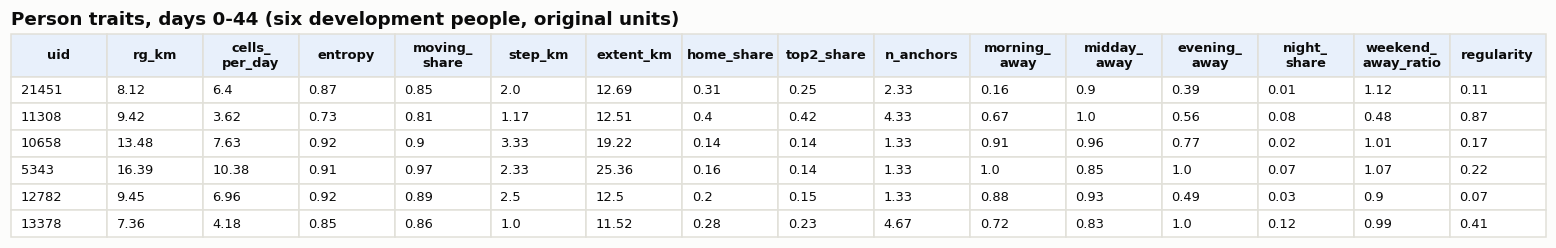

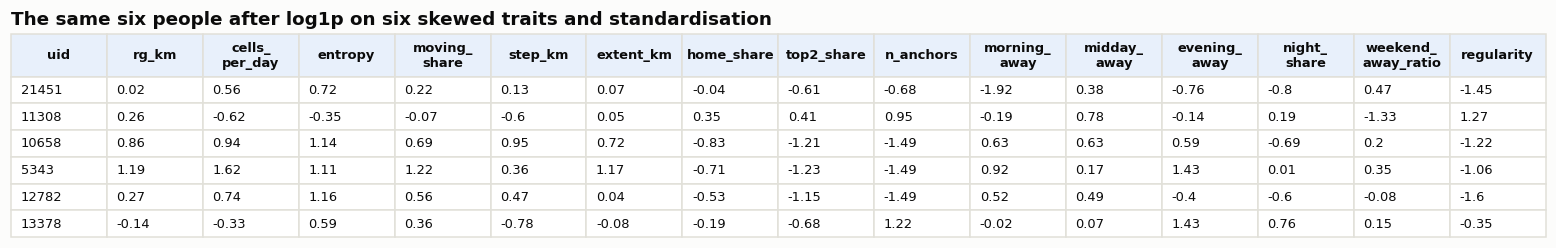

In [7]:
def table_png(df, name, title, width=11):
    fig, ax = plt.subplots(figsize=(width, 0.3 * len(df) + 0.6)); ax.axis("off"); ax.grid(False)
    cols = [c.replace("_", "_\n", 1) if len(c) > 10 else c for c in df.columns]           # long names on two lines
    tb = ax.table(cellText=df.astype(str).values, colLabels=cols, cellLoc="left", bbox=[0, 0, 1, 1])
    tb.auto_set_font_size(False); tb.set_fontsize(8.5)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#e1e0d9")
        if r == 0: cell.set_facecolor("#e8f0fb"); cell.set_text_props(weight="bold"); cell.set_height(cell.get_height() * 1.6)
    ax.set_title(title, loc="left", fontweight="bold"); save(fig, name)

from sklearn.preprocessing import StandardScaler
LOG = ["step_km", "weekend_away_ratio", "extent_km", "night_share", "rg_km", "cells_per_day"]   # skewness about 1 or more

def prepare(df):
    x = df[BEHAVIOUR].copy()
    for c in LOG: x[c] = np.log1p(x[c])
    return x

dev = ref[ref.split == "dev"]
scaler = StandardScaler().fit(prepare(dev))                       # fitted on development people, days 0-44, then frozen
Z = scaler.transform(prepare(dev))
print(f"matrix for PCA and clustering: {Z.shape[0]:,} development people x {Z.shape[1]} traits")
print("skewness after log1p:", prepare(dev)[LOG].skew().round(2).to_dict())
print("column means after scaling (should be 0):", np.abs(Z.mean(axis=0)).max().round(6), "| std (should be 1):", Z.std(axis=0).round(3).min(), Z.std(axis=0).round(3).max())

sample = dev.sample(6, random_state=SEED)
before = sample[BEHAVIOUR].round(2).reset_index()
after = pd.DataFrame(scaler.transform(prepare(sample)), columns=BEHAVIOUR, index=sample.index).round(2).reset_index()
table_png(before, "t07_person_traits", "Person traits, days 0-44 (six development people, original units)", 18)
table_png(after, "t08_person_traits_scaled", "The same six people after log1p on six skewed traits and standardisation", 18)

## The prepared table

After the log transform the six skewed traits sit between -0.33 and 1.66 skewness; the weekend to workday ratio stays the most lopsided because a few people are away from home far more on weekends than on workdays, and that is a real difference worth keeping. Standardising gives every trait mean 0 and standard deviation 1 on the development people, so a trait measured in kilometres and a trait measured as a share weigh the same. The two tables show the same six people before and after: person 5343, for example, has the largest radius and the most cells per day of the six and ends up more than one standard deviation above average on both, while person 11308, with 4.3 anchor places and a regularity of 0.87, is the one above average on rootedness and below on spread. The prepared matrix is 17,164 development people by 15 traits, numeric and without labels, which is what both PCA and clustering need.

eigenvalues: [7.41 1.72 1.44 1.04 0.82 0.64 0.44 0.42 0.37 0.23 0.19 0.13 0.07 0.06
 0.02]
explained variance %: [49.4 11.5  9.6  6.9  5.4  4.3  2.9  2.8  2.4  1.6  1.3  0.8  0.5  0.4
  0.1]
cumulative %:         [ 49.4  60.9  70.5  77.4  82.8  87.1  90.1  92.9  95.3  96.9  98.1  99.
  99.5  99.9 100. ]
components for 80%: 5 | for 90%: 7 | eigenvalue above 1 (Kaiser): 4
SVD check, eigenvalues equal: True | directions equal up to sign: True


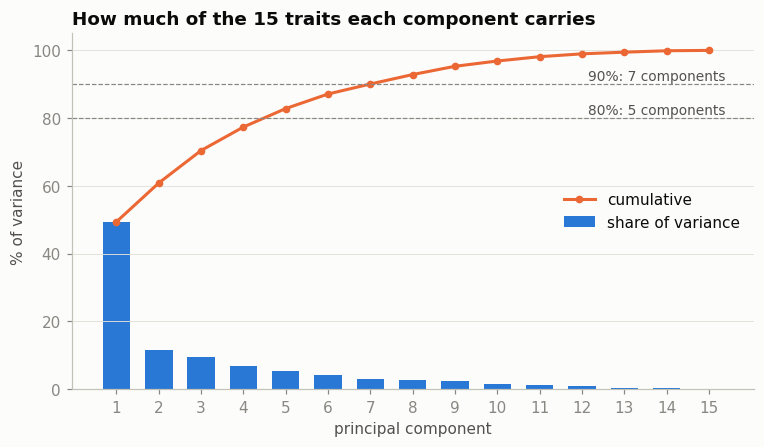

                     PC1   PC2   PC3   PC4   PC5
rg_km              -0.27  0.21 -0.23  0.35 -0.00
cells_per_day      -0.31  0.18 -0.15 -0.05  0.06
entropy            -0.33  0.01  0.24 -0.19  0.13
moving_share       -0.29  0.02  0.29 -0.25  0.23
step_km            -0.28  0.22 -0.11  0.03 -0.24
extent_km          -0.28  0.19 -0.26  0.39  0.04
home_share          0.32  0.22 -0.16 -0.14  0.07
top2_share          0.34  0.02 -0.19  0.15 -0.20
n_anchors           0.16 -0.39  0.25  0.21  0.50
morning_away       -0.25 -0.39 -0.10  0.12 -0.07
midday_away        -0.24 -0.45 -0.23 -0.04 -0.02
evening_away       -0.24 -0.08  0.19  0.39  0.14
night_share         0.14  0.11 -0.47  0.08  0.69
weekend_away_ratio  0.04  0.47  0.49  0.29  0.13
regularity          0.21 -0.21  0.14  0.54 -0.23


In [8]:
from sklearn.decomposition import PCA
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
k80, k90 = int(np.argmax(cum >= 0.8) + 1), int(np.argmax(cum >= 0.9) + 1)
print("eigenvalues:", pca.explained_variance_.round(2))
print("explained variance %:", (evr * 100).round(1))
print("cumulative %:        ", (cum * 100).round(1))
print(f"components for 80%: {k80} | for 90%: {k90} | eigenvalue above 1 (Kaiser): {(pca.explained_variance_ > 1).sum()}")

# the same directions straight from the SVD of Z, as in class: X = U S V^T, eigenvalue = s^2 / (n - 1)
U, s, Vt = np.linalg.svd(Z, full_matrices=False)
print("SVD check, eigenvalues equal:", np.allclose(s**2 / (len(Z) - 1), pca.explained_variance_),
      "| directions equal up to sign:", np.allclose(np.abs(Vt), np.abs(pca.components_)))

pcs = np.arange(1, len(evr) + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(pcs, evr * 100, color=C[0], width=0.65, label="share of variance")
ax.plot(pcs, cum * 100, color=C[1], marker="o", ms=4, lw=2, label="cumulative")
for lvl, k in [(80, k80), (90, k90)]:
    ax.axhline(lvl, color="#898781", lw=0.8, ls="--"); ax.text(15.4, lvl + 1.2, f"{lvl}%: {k} components", ha="right", fontsize=9, color="#52514e")
ax.set(xlabel="principal component", ylabel="% of variance", xticks=pcs, ylim=(0, 105)); ax.xaxis.grid(False)
ax.set_title("How much of the 15 traits each component carries"); ax.legend(loc="center right", frameon=False)
save(fig, "f17_pca_people_scree")

load = pd.DataFrame(pca.components_[:5].T, index=BEHAVIOUR, columns=[f"PC{i}" for i in range(1, 6)])
print(load.round(2).to_string())

## How few traits: five components carry 83%

PCA on the 17,164 x 15 standardised matrix gives eigenvalues 7.41, 1.72, 1.44, 1.04 and 0.82 for the first five components, and the SVD of the same matrix gives the same values (eigenvalue = s² / (n − 1)) and the same directions, as it should. The first component alone carries 49.4% of the variation in fifteen traits. Five components carry 82.8% and seven carry 90.1%; four have an eigenvalue above 1. I keep five, by the 80% rule, which is also where the bars flatten out in the scree plot: from the sixth component on each adds less than 5%.

Reading the loadings. PC1 loads every spread trait one way (radius, cells per day, entropy, steps, extent, all 0.27 to 0.33) and the two rootedness shares the other way (−0.32 and −0.34): it is one axis from people who stay around a couple of places to people who range widely. PC2 sets workday mornings and middays away from home and many anchor places against the weekend to workday ratio: a weekday routine axis. PC3 is mostly the weekend ratio against night records, and PC4 is regularity together with long days (extent, radius, evening away), a regular long day. PC5 is almost only night share and number of anchors.

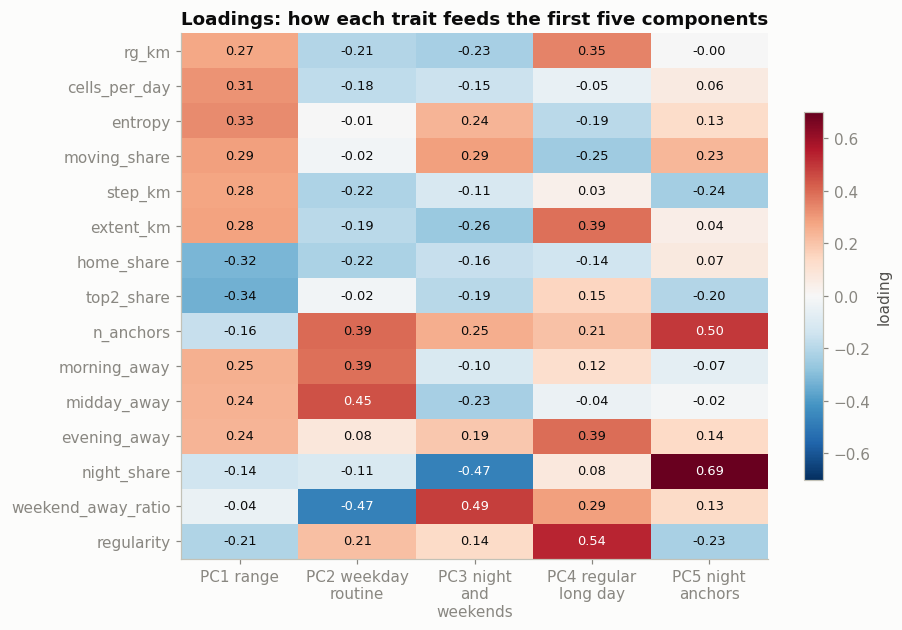

correlation of the held-out recording traits with each component:
                  PC1 range  PC2 weekday routine  PC3 night and weekends  PC4 regular long day  PC5 night anchors
records_per_day      -0.26                -0.01                   -0.42                  0.08               0.22
days_share           -0.10                 0.05                   -0.03                 -0.03               0.00
span_h               -0.44                -0.00                   -0.53                  0.06               0.39


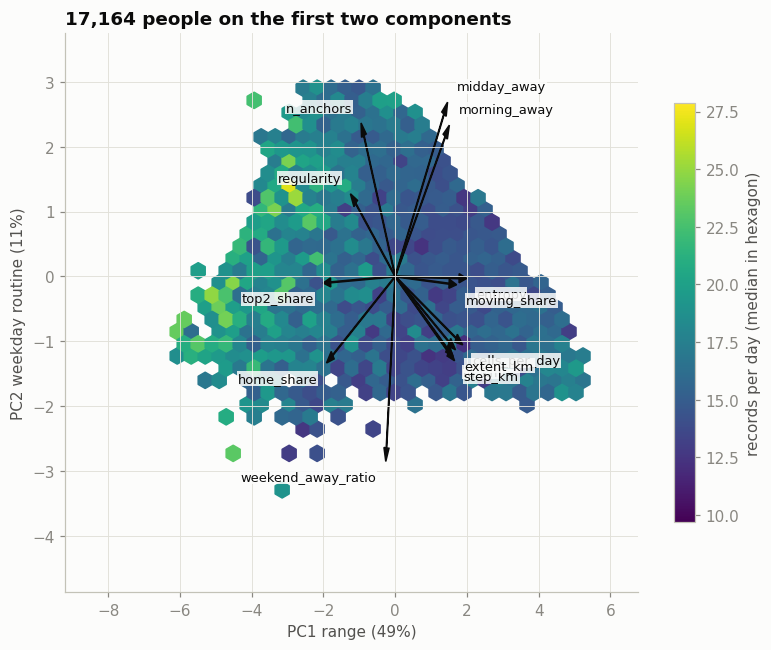

In [9]:
import textwrap
pca.components_[:2] *= -1                                  # sign is arbitrary; flipped so that higher PC1 = wider range, higher PC2 = weekday routine
NAMES = ["PC1 range", "PC2 weekday routine", "PC3 night and weekends", "PC4 regular long day", "PC5 night anchors"]
S = pca.transform(Z)
load = pd.DataFrame(pca.components_[:5].T, index=BEHAVIOUR, columns=NAMES)

fig, ax = plt.subplots(figsize=(8.6, 6.2)); ax.grid(False)
im = ax.imshow(load.values, cmap="RdBu_r", vmin=-0.7, vmax=0.7, aspect="auto")
for i in range(load.shape[0]):
    for j in range(load.shape[1]):
        v = load.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.4 else "#0b0b0b")
ax.set_xticks(range(5)); ax.set_xticklabels([textwrap.fill(n, 11) for n in NAMES]); ax.set_yticks(range(len(BEHAVIOUR))); ax.set_yticklabels(BEHAVIOUR)
ax.set_title("Loadings: how each trait feeds the first five components"); fig.colorbar(im, ax=ax, shrink=0.7, label="loading")
save(fig, "f18_pca_people_loadings")

obs = dev[OBSERVABILITY]
cor = pd.DataFrame({n: [np.corrcoef(S[:, j], obs[c])[0, 1] for c in OBSERVABILITY] for j, n in enumerate(NAMES)}, index=OBSERVABILITY)
print("correlation of the held-out recording traits with each component:\n", cor.round(2).to_string())

# biplot: people as a density coloured by records per day (held out of the fit), the strongest traits as arrows
fig, ax = plt.subplots(figsize=(8.4, 6.6))
lo, hi = np.percentile(obs.records_per_day, [5, 95])
hb = ax.hexbin(S[:, 0], S[:, 1], C=obs.records_per_day, reduce_C_function=np.median, gridsize=45, cmap="viridis", mincnt=8, vmin=lo, vmax=hi)
fig.colorbar(hb, ax=ax, shrink=0.75, label="records per day (median in hexagon)")
sc = 6
arrows = pd.DataFrame({"x": pca.components_[0] * sc, "y": pca.components_[1] * sc}, index=BEHAVIOUR)
arrows = arrows[np.hypot(arrows.x, arrows.y) > 1.6]
for t, (x, y) in arrows.iterrows():
    ax.arrow(0, 0, x, y, color="#0b0b0b", width=0.015, head_width=0.14, length_includes_head=True)
    ax.annotate(t, (x, y), xytext=(6 * np.sign(x), 6 * np.sign(y)), textcoords="offset points", fontsize=8.5,
                ha="left" if x > 0 else "right", va="bottom" if y > 0 else "top", bbox=dict(fc="#fcfcfb", ec="none", alpha=0.85, pad=0.4))
ax.set(xlim=np.percentile(S[:, 0], [0.2, 99.8]) + [-0.5, 1.5], ylim=np.percentile(S[:, 1], [0.2, 99.8]) + [-0.5, 0.5])
ax.set(xlabel=f"{NAMES[0]} ({evr[0]:.0%})", ylabel=f"{NAMES[1]} ({evr[1]:.0%})")
ax.set_title("17,164 people on the first two components")
save(fig, "f19_pca_people_biplot")

## What the axes mean, and which ones are about recording

The signs of principal components are arbitrary, so PC1 and PC2 were flipped to read naturally: a high PC1 means a wide range, a high PC2 means a strong weekday routine. In the biplot the people form a triangle. Along PC1 they run from the rooted corner on the left (home share, top-two share) to the wide-ranging side on the right, where radius, extent, steps, cells per day and entropy all point together. PC2 then splits the wide-ranging side: up are people away every workday morning and midday with several fixed places and regular days, down are people whose time away tilts to the weekend.

The three recording traits were left out of the fit and checked afterwards. PC2 has nothing to do with them (correlations −0.01, 0.05 and 0.00), so the weekday routine axis is pure behaviour. PC1 correlates −0.44 with the daily active span and −0.26 with records per day, and the colours show it: rooted people are recorded more per day than wide-ranging ones. PC3 is the most tangled with recording (−0.42 with records per day, −0.53 with active span), so it is partly a measure of how well a person is seen, and I read it with that caution from here on.

In [14]:
# k-means and the linear algebra run on OpenMP / BLAS threads. Timed on this node: one k-means fit (k=5, n_init=10)
# takes 0.35 s on 1 thread, 0.19 s on 4 and 3.88 s on 12, so the rest of the notebook runs on 4
import os
from threadpoolctl import threadpool_limits, threadpool_info
print("cores on the node:", os.cpu_count(), "| cores this job may use:", len(os.sched_getaffinity(0)))
threadpool_limits(4)
print("threads now:", {i["internal_api"]: i["num_threads"] for i in threadpool_info()})

cores on the node: 64 | cores this job may use: 12
threads now: {'openblas': 4, 'openmp': 4}


In [13]:
import time
for n in [1, 4, 12]:
    with threadpool_limits(n):
        t = time.time(); KMeans(5, n_init=10, random_state=SEED).fit(Z); a = time.time() - t
        t = time.time(); silhouette_score(Z[sub], km_fit[5].labels_[sub] if 5 in km_fit else KMeans(5, n_init=1, random_state=SEED).fit(Z).labels_[sub]); b = time.time() - t
    print(f"{n:2d} threads: one k-means fit {a:.2f} s | one silhouette {b:.2f} s")

 1 threads: one k-means fit 0.35 s | one silhouette 0.23 s
 4 threads: one k-means fit 0.19 s | one silhouette 0.20 s
12 threads: one k-means fit 3.88 s | one silhouette 0.37 s


          wcss  silhouette  stability  stability_low                                                       sizes
k                                                                                                               
2   172617.700       0.291      0.977          0.951                                               [10024, 7140]
3   145252.721       0.213      0.972          0.945                                          [3535, 6492, 7137]
4   134535.908       0.168      0.843          0.527                                    [2237, 5319, 6015, 3593]
5   125313.984       0.174      0.761          0.556                              [5530, 5285, 1179, 3599, 1571]
6   117900.984       0.149      0.829          0.715                        [3890, 1428, 3020, 1028, 4556, 3242]
7   112717.623       0.146      0.787          0.630                   [3476, 1938, 3998, 2909, 2633, 1216, 994]
8   108081.387       0.143      0.825          0.725             [3046, 2112, 2657, 787, 1278, 1

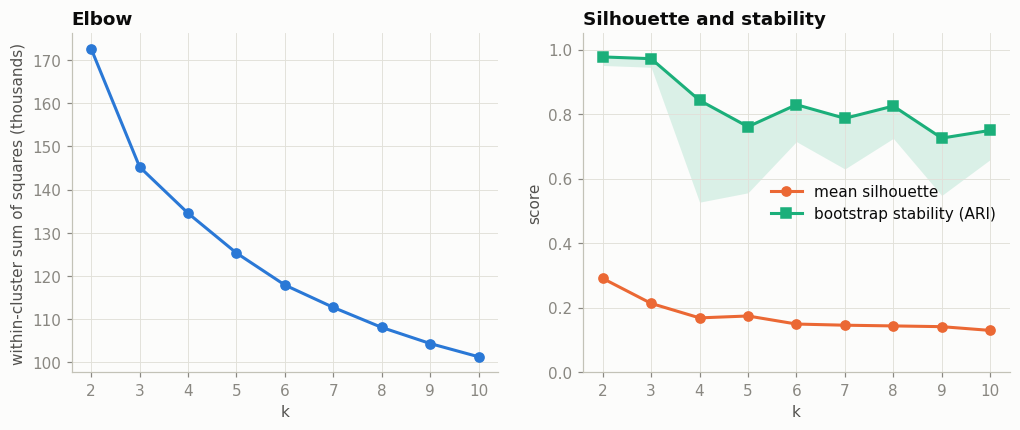

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
rng = np.random.default_rng(SEED)
sub = rng.choice(len(Z), 5000, replace=False)              # same 5,000 people for every silhouette
KS = range(2, 11)
km_fit, rows = {}, []
for k in KS:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    km_fit[k] = km
    rows.append((k, km.inertia_, silhouette_score(Z[sub], km.labels_[sub])))
res = pd.DataFrame(rows, columns=["k", "wcss", "silhouette"]).set_index("k")

# stability: two k-means fits on two bootstrap samples, both used to label all development people, agreement by adjusted Rand index
B = 20
for k in KS:
    aris = []
    for b in range(B):
        r = np.random.default_rng(SEED + b)
        f1 = KMeans(k, n_init=3, random_state=b).fit(Z[r.choice(len(Z), len(Z))])
        f2 = KMeans(k, n_init=3, random_state=B + b).fit(Z[r.choice(len(Z), len(Z))])
        aris.append(adjusted_rand_score(f1.predict(Z), f2.predict(Z)))
    res.loc[k, "stability"], res.loc[k, "stability_low"] = np.mean(aris), np.percentile(aris, 10)
res["sizes"] = [np.bincount(km_fit[k].labels_).tolist() for k in KS]
print(res.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(res.index, res.wcss / 1e3, color=C[0], marker="o", lw=2)
axes[0].set(xlabel="k", ylabel="within-cluster sum of squares (thousands)", title="Elbow")
axes[1].plot(res.index, res.silhouette, color=C[1], marker="o", lw=2, label="mean silhouette")
axes[1].plot(res.index, res.stability, color=C[2], marker="s", lw=2, label="bootstrap stability (ARI)")
axes[1].fill_between(res.index, res.stability_low, res.stability, color=C[2], alpha=0.15, lw=0)
axes[1].set(xlabel="k", ylabel="score", ylim=(0, 1.05), title="Silhouette and stability")
axes[1].legend(frameon=False, loc="center right")
save(fig, "f20_kmeans_choose_k")

## Choosing k

The elbow has no clear bend: the within-cluster sum of squares falls by 27,000 from k = 2 to 3 and then by ever smaller steps. The mean silhouette is highest at k = 2 (0.29) and falls to 0.21 at k = 3 and about 0.15 from k = 6 on. A silhouette that low says the people do not form separate islands, they form one continuous cloud, so any k cuts it rather than finds it. That makes a second criterion necessary. For stability, k-means was fitted on two bootstrap samples of the development people, both fits labelled everyone, and the agreement was measured with the adjusted Rand index, twenty times per k. k = 2 and 3 come back almost identical every time (0.98 and 0.97). k = 4 and 5 do not (0.84 and 0.76, with bad draws down to 0.53 and 0.56). k = 6 recovers to 0.83, with its worst draws at 0.72.

So the silhouette's answer is k = 2, which only splits the population along PC1 into people who stay close and people who range wide. k = 3 is the most robust description with some content. I use k = 6 as the working partition: it is as stable as anything above k = 3, and it separates kinds of movers that k = 3 merges, such as people who commute to the same place every workday and people who move as far but without a fixed place. The tab shows k = 3, 5 and 6 side by side, and the frozen-types test below is repeated for k = 3 as a check.

A side note on the cluster: k-means here runs on OpenMP threads, and on this node one fit took 0.35 s with 1 thread, 0.19 s with 4 and 3.88 s with 12, so the notebook runs it on 4.

                    far roamers  mid-range movers  regular commuters  local regulars  weekend movers  homebodies
rg_km                     14.51              8.80               7.13            5.81            7.04        3.07
cells_per_day              8.53              5.68               3.96            3.65            3.64        2.26
entropy                    0.90              0.84               0.75            0.68            0.72        0.55
moving_share               0.93              0.88               0.80            0.74            0.78        0.63
step_km                    3.67              2.22               1.32            1.10            1.20        0.74
extent_km                 23.63             12.92              10.83            8.73           10.10        4.55
home_share                 0.13              0.25               0.20            0.51            0.53        0.76
top2_share                 0.17              0.27               0.38            0.48            

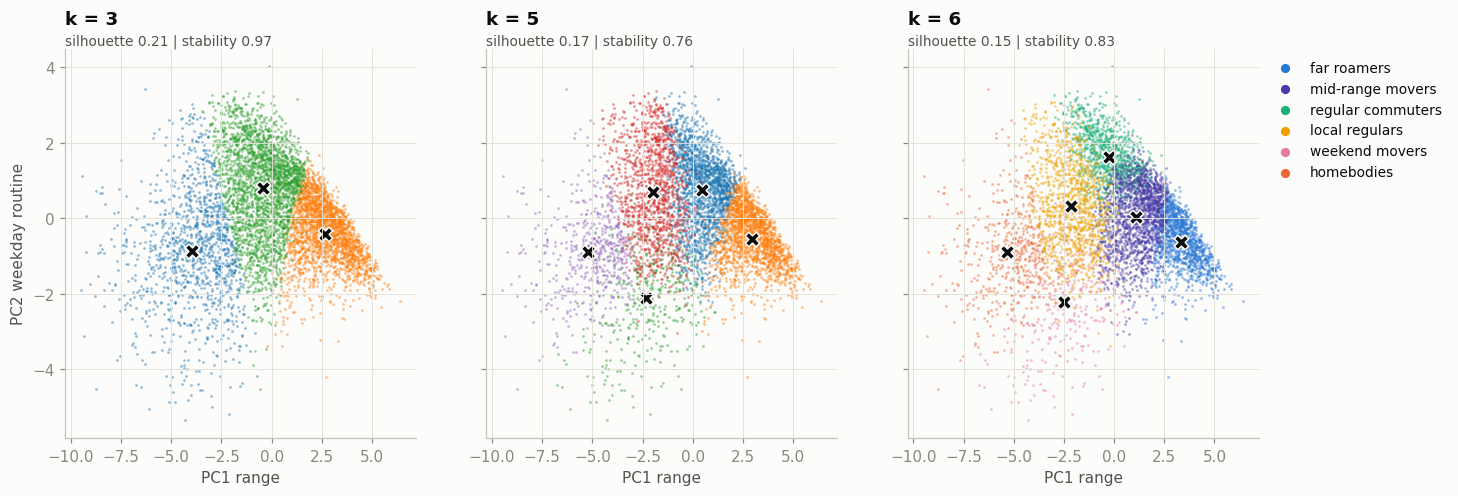

In [17]:
K = 6
km6 = km_fit[K]
cent = pd.DataFrame(scaler.inverse_transform(km6.cluster_centers_), columns=BEHAVIOUR)
for c in LOG: cent[c] = np.expm1(cent[c])
cent["people"] = np.bincount(km6.labels_)

# names from the centroids, not from label numbers
name = {}
name[cent.home_share.idxmax()] = "homebodies"
name[cent.weekend_away_ratio.idxmax()] = "weekend movers"
name[cent.rg_km.idxmax()] = "far roamers"
rest = cent.drop(index=list(name))
name[rest.regularity.idxmax()] = "regular commuters"
rest = rest.drop(index=rest.regularity.idxmax())
name[rest.rg_km.idxmax()] = "mid-range movers"
name[rest.rg_km.idxmin()] = "local regulars"
ORDER = ["far roamers", "mid-range movers", "regular commuters", "local regulars", "weekend movers", "homebodies"]
cent.index = cent.index.map(name); cent = cent.loc[ORDER]
print(cent.round(2).T.to_string())
lab6 = pd.Series(km6.labels_, index=dev.index).map(name)
COL = dict(zip(ORDER, [C[0], C[6], C[2], C[3], C[4], C[1]]))

# k = 3, 5 and 6 side by side on the first two components (a 6,000-person sample keeps the dots readable)
show = rng.choice(len(Z), 6000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, k in zip(axes, [3, 5, 6]):
    lab = km_fit[k].labels_
    for j in range(k):
        m = lab[show] == j
        ax.scatter(S[show][m, 0], S[show][m, 1], s=3, alpha=0.5, color=COL[name[j]] if k == K else plt.cm.tab10(j), lw=0)
    cc = pca.transform(km_fit[k].cluster_centers_)
    ax.scatter(cc[:, 0], cc[:, 1], s=90, marker="X", color="#0b0b0b", edgecolor="white", lw=1)
    ax.set_title(f"k = {k}", fontsize=12, pad=16); ax.text(0.0, 1.0, f"silhouette {res.silhouette[k]:.2f} | stability {res.stability[k]:.2f}", transform=ax.transAxes, fontsize=9, color="#52514e", va="bottom")
    ax.set_xlabel(NAMES[0])
axes[0].set_ylabel(NAMES[1])
for nm in ORDER: axes[2].scatter([], [], s=25, color=COL[nm], label=nm)
axes[2].legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "f21_kmeans_k3_k5_k6")

## Six kinds of movers

The six centroids, back in the original units, read as six recognisable ways of living a fortnight. Names come from the centroids by rule (largest home share, largest weekend ratio, largest radius, then regularity), not from label numbers.

Far roamers (3,890 development people) range widest: a radius of 14.5 km, 8.5 different cells a day, a typical day reaching 24 km from home, only 13% of records at home, fewer than two fixed places, and the lowest regularity of all (0.27). Mid-range movers (4,556) are the same kind of life at about half the scale, 8.8 km and 5.7 cells a day, and almost as irregular (0.39). Regular commuters (3,020) are away 90% of workday mornings and 96% of middays and spend 78% of workday middays at the same place, with the most fixed places (4.1). Local regulars (3,242) stay within about 6 km, keep half their records at home and have the most night records after the homebodies (12%). Weekend movers (1,028) are away from home more than twice as much on weekends as on workdays (ratio 2.19) and are at home most workday mornings and middays. Homebodies (1,428) keep 76% of their records in the home block, move within 3 km and are the least often away at any time of day.

On the first two components the six kinds lie side by side in the triangle: far roamers at the wide-ranging end of PC1, regular commuters at the top of PC2, homebodies at the rooted end. Weekend movers overlap with homebodies and local regulars in this view because what sets them apart, the weekend ratio, loads mostly on PC3.

12,476,665 records of 17,164 development people


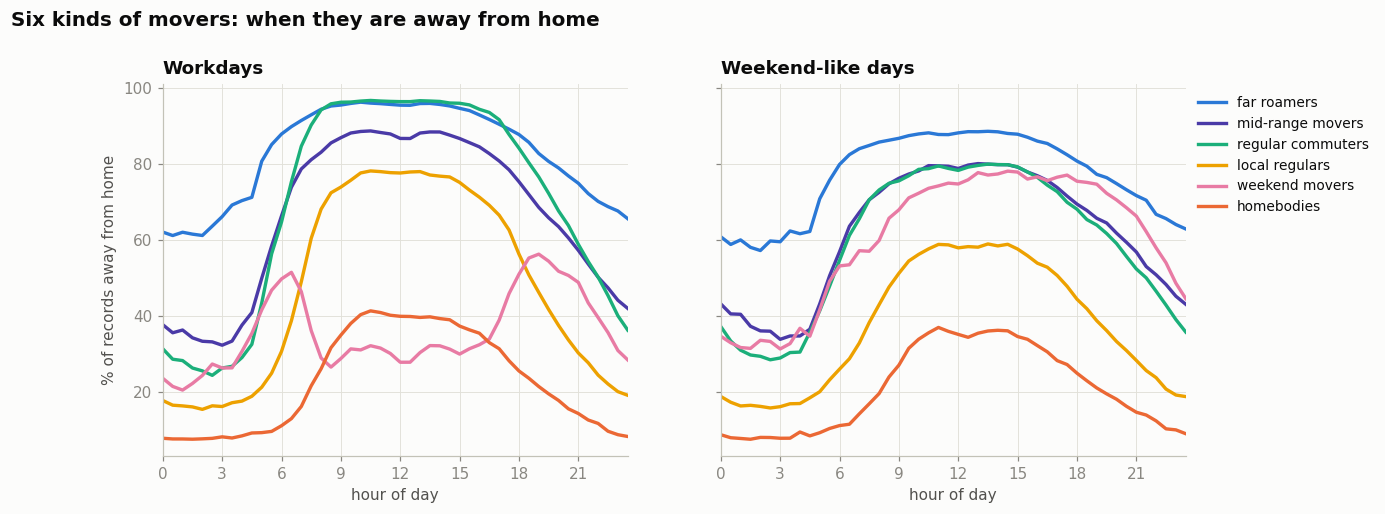

t                    6     16    24    38    46
kind                                           
far roamers        66.0  94.0  95.0  83.0  68.0
homebodies          8.0  26.0  40.0  22.0   9.0
local regulars     16.0  68.0  78.0  46.0  20.0
mid-range movers   32.0  83.0  87.0  69.0  44.0
regular commuters  26.0  94.0  96.0  77.0  40.0
weekend movers     26.0  29.0  28.0  56.0  31.0


In [18]:
# rhythm portraits: share of records away from the home block in every half hour, days 0-44, development people by kind
r = an[(an.d <= 44) & an.uid.isin(lab6.index)][["uid", "t", "x", "y", "workday", "weekend"]]
h = anc.home.reindex(r.uid).to_numpy()
r["away"] = np.maximum(np.abs(r.x.to_numpy() - h // 256), np.abs(r.y.to_numpy() - h % 256)) > 1
r["kind"] = lab6.reindex(r.uid).to_numpy()
r["day"] = np.where(r.workday, "workdays", np.where(r.weekend, "weekend-like days", "holiday-like"))
rhythm = r[r.day != "holiday-like"].groupby(["day", "kind", "t"]).away.mean().unstack("t")
print(f"{len(r):,} records of {r.uid.nunique():,} development people")

hours = np.arange(48) / 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, day in zip(axes, ["workdays", "weekend-like days"]):
    for nm in ORDER:
        ax.plot(hours, rhythm.loc[(day, nm)] * 100, color=COL[nm], lw=2.2, label=nm)
    ax.set(xlabel="hour of day", xticks=range(0, 25, 3), xlim=(0, 23.5), title=day.capitalize())
axes[0].set_ylabel("% of records away from home")
axes[1].legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Six kinds of movers: when they are away from home", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.03)
save(fig, "f22_kinds_daily_rhythm")
print((rhythm.loc["workdays"].iloc[:, [6, 16, 24, 38, 46]] * 100).round(0).to_string())
del r, h

## When each kind is away from home

The curves give each kind its own shape of day, without anything in the clustering having been told about hours. On workdays regular commuters and far roamers are both away more than 94% of the time between 8 am and 3 pm, but the commuters leave later and come home earlier: at 3 am a commuter is away 26% of the time and a far roamer 66%. Local regulars follow the commuter shape at a lower level, 78% away at noon. Homebodies never pass 41%. Weekend movers are the odd ones: on workdays they leave early (51% away at 6:30), are mostly home through the middle of the day (28% at noon) and go out again in the evening (56% at 7 pm), while on weekend-like days they are away as much as the commuters. On weekends the other kinds flatten out and the differences between commuters, mid-range movers and weekend movers almost disappear.

One thing does not fit the picture of a home: far roamers are away from their night anchor 60% of the time even between midnight and 3 am. For them the most frequent night cell is a weak anchor, which raises the question of whether some of them work at night or sleep in different places.

In [19]:
# night-mobile: many night records (at least 15%) and fewer than half of them in the night-anchor block.
# fits night work, driving or sleeping in different places alike, so it is a flag, not a label; held out of every fit
f = an[(an.d <= 44) & (an.t < 10) & an.uid.isin(lab6.index)][["uid", "x", "y"]]
h = anc.home.reindex(f.uid).to_numpy()
near = pd.Series(np.maximum(np.abs(f.x.to_numpy() - h // 256), np.abs(f.y.to_numpy() - h % 256)) <= 1, index=f.uid.to_numpy())
night = pd.DataFrame({"night_records": near.groupby(level=0).size(), "night_in_home_block": near.groupby(level=0).mean()})
night = night.reindex(lab6.index).fillna({"night_records": 0})
night["night_mobile"] = (dev.night_share >= 0.15) & (night.night_in_home_block < 0.5)
night["kind"] = lab6
print(f"night-mobile development people: {night.night_mobile.sum():,} ({night.night_mobile.mean():.1%})")
tab = night.groupby("kind").agg(people=("kind", "size"), night_mobile=("night_mobile", "sum"), share=("night_mobile", "mean"),
                                night_in_home_block=("night_in_home_block", "median")).loc[ORDER]
print(tab.round(3).to_string())
del f, h, near

night-mobile development people: 711 (4.1%)
                   people  night_mobile  share  night_in_home_block
kind                                                               
far roamers          3890           345  0.089                0.493
mid-range movers     4556           173  0.038                0.792
regular commuters    3020            48  0.016                0.857
local regulars       3242           105  0.032                0.928
weekend movers       1028            23  0.022                0.794
homebodies           1428            17  0.012                0.988


## Night-mobile people

Some people may work at night, drive for a living or sleep in more than one place, and for them the most frequent night cell is not a home. The records cannot say which of these it is, so instead of a label there is a flag: at least 15% of a person's records fall between midnight and 5 am, and fewer than half of those are in the night-anchor block. 711 development people, 4.1%, are night-mobile. Nobody is removed and the flag is not used in any fit. It concentrates in one kind: 345 of the 711 are far roamers, 9% of that kind against 1 to 4% in every other, and the median far roamer has only 49% of their night records near the night anchor, against 79 to 99% in the other kinds. So part of what makes a far roamer is having no fixed place at night, and that is the kind where "home" means least. The flag follows these people through the rest of the notebook.

In [21]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist
hs = np.random.default_rng(SEED + 13).choice(len(Z), 3000, replace=False)   # own generator, so the sample does not depend on cell order
Zh = Z[hs]
D = pdist(Zh, metric="cosine")                              # cosine distance = 1 - cosine similarity
print(f"{len(D):,} pairwise distances; rows with a norm below 0.5 (unstable angle): {(np.linalg.norm(Zh, axis=1) < 0.5).sum()}")
rows = []
links = {m: linkage(D, method=m) for m in ["average", "complete"]}
for m, L in links.items():
    for k in range(2, 9):
        lab = fcluster(L, k, criterion="maxclust")
        rows.append((m, k, silhouette_score(Zh, lab, metric="cosine"), adjusted_rand_score(lab, km_fit[k].labels_[hs]), sorted(np.bincount(lab)[1:].tolist(), reverse=True)))
hc = pd.DataFrame(rows, columns=["linkage", "k", "silhouette_cosine", "ARI_vs_kmeans", "sizes"])
print(hc.round(3).to_string(index=False))

4,498,500 pairwise distances; rows with a norm below 0.5 (unstable angle): 0
 linkage  k  silhouette_cosine  ARI_vs_kmeans                                   sizes
 average  2              0.372          0.555                            [1971, 1029]
 average  3              0.331          0.392                       [1394, 1029, 577]
 average  4              0.316          0.387                  [1171, 1029, 577, 223]
 average  5              0.288          0.387              [1171, 1029, 577, 178, 45]
 average  6              0.291          0.386          [1029, 981, 577, 190, 178, 45]
 average  7              0.278          0.374      [1029, 981, 517, 190, 178, 60, 45]
 average  8              0.285          0.394  [981, 827, 517, 202, 190, 178, 60, 45]
complete  2              0.366          0.538                             [2082, 918]
complete  3              0.350          0.538                        [1250, 918, 832]
complete  4              0.322          0.405                  

## Hierarchical clustering with cosine distance

Agglomerative clustering starts from every person as a group of one and merges the two closest groups again and again until one group is left; where to cut the resulting tree is decided afterwards. A full tree of 17,164 people would need 147 million pairwise distances, so it is built on a random sample of 3,000 development people (4.5 million distances). The distance is cosine: 1 minus the cosine of the angle between two people's standardised trait vectors. It asks whether two people deviate from the average in the same directions, regardless of how far, so a mild and an extreme far roamer count as alike. Cosine is unstable for rows close to the average, where the angle is decided by noise; no row in the sample is that close.

Two ways of measuring the distance between groups give two different trees. Average linkage peels off small groups as k grows, 45 and then 60 people, the chaining the class notes warn about. Complete linkage, which merges by the farthest pair, keeps the groups balanced, and its cosine silhouette is 0.37 at k = 2, 0.35 at k = 3 and 0.32 at k = 4, then falls to 0.28 and 0.23. The tree therefore suggests three or four groups, more than the silhouette of k-means (two) and fewer than the six I work with. Agreement with k-means at the same k is moderate (adjusted Rand 0.54 at k = 2 and 3, about 0.36 to 0.40 above). An earlier run on a different 3,000-person sample gave a similar but not identical table, so the tree's suggestion is softer than the bootstrapped k-means result.

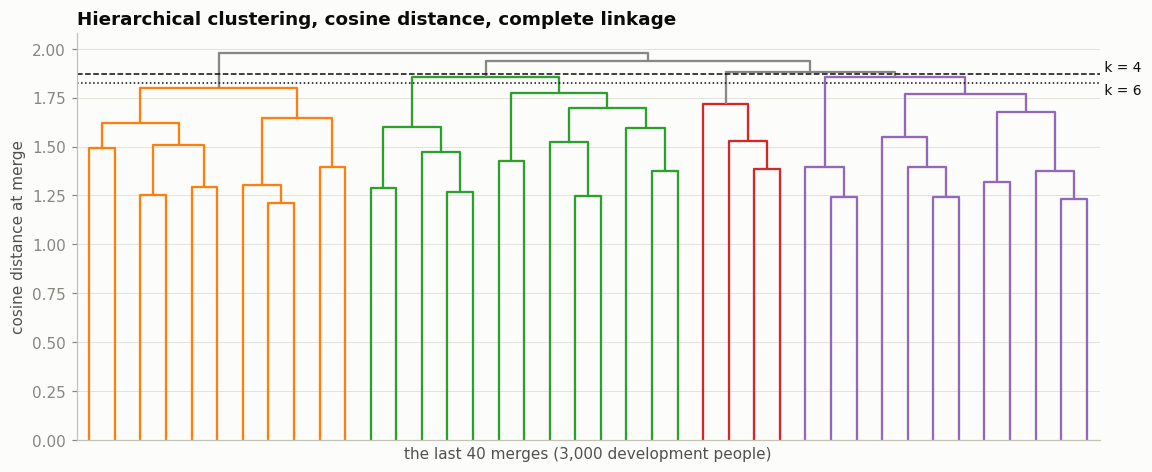

col_0                 far roamers  mid-range movers  regular commuters  local regulars  weekend movers  homebodies
hierarchical cluster                                                                                              
1                               0                43                 20             468             142         245
2                             578               340                  5               0               0           0
3                             110               167                 14              13              23           0
4                               0               108                 73              24               3           0
5                               1                11                 36              56               0           0
6                               3                94                387              35               0           1


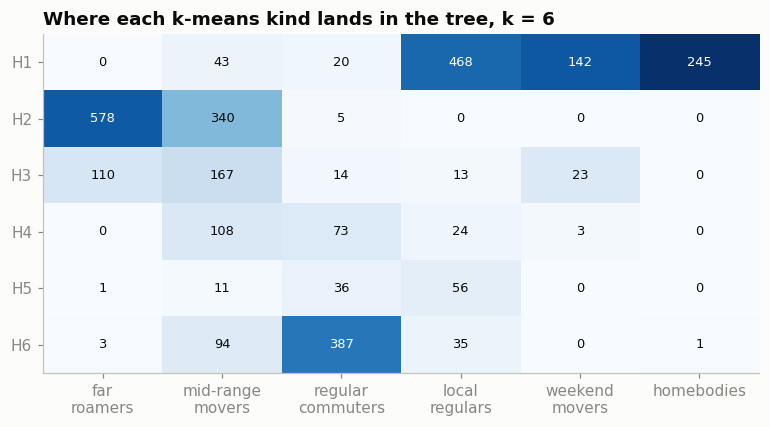

In [22]:
L = links["complete"]
cut = {k: (L[-k, 2] + L[-k + 1, 2]) / 2 for k in [3, 4, 6]}          # a height between the merges that leave k and k - 1 clusters
fig, ax = plt.subplots(figsize=(12, 4.8)); ax.xaxis.grid(False)
dendrogram(L, truncate_mode="lastp", p=40, color_threshold=cut[4], above_threshold_color="#898781", no_labels=True, ax=ax)
for k, ls, va in [(4, "--", "bottom"), (6, ":", "top")]:
    ax.axhline(cut[k], color="#0b0b0b", lw=1, ls=ls); ax.text(ax.get_xlim()[1], cut[k], f" k = {k}", va=va, fontsize=9)
ax.set(ylabel="cosine distance at merge", xlabel="the last 40 merges (3,000 development people)")
ax.set_title("Hierarchical clustering, cosine distance, complete linkage")
save(fig, "f23_hclust_dendrogram")

h6 = fcluster(L, 6, criterion="maxclust")
ct = pd.crosstab(pd.Series(h6, name="hierarchical cluster"), lab6.iloc[hs].rename("k-means kind").values)[ORDER]
print(ct.to_string())
fig, ax = plt.subplots(figsize=(8.4, 4)); ax.grid(False)
share = ct / ct.sum(axis=0)
im = ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f"{ct.values[i, j]}", ha="center", va="center", fontsize=8.5, color="white" if share.values[i, j] > 0.55 else "#0b0b0b")
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels([textwrap.fill(n, 10) for n in ORDER]); ax.set_yticks(range(share.shape[0])); ax.set_yticklabels([f"H{i}" for i in ct.index])
ax.set_title("Where each k-means kind lands in the tree, k = 6")
save(fig, "f24_hclust_vs_kmeans")

## The tree and k-means compared

Cutting the tree at six groups and laying it against the six k-means kinds of the same 3,000 people shows where the two methods agree. The wide-ranging side is one branch in both: H2 holds 578 far roamers and 340 mid-range movers and almost nobody else. Regular commuters have their own branch, H6, with 387 of the 534 in the sample. The rooted side is a single branch in the tree, H1, holding local regulars (468), weekend movers (142) and homebodies (245): what k-means splits into three kinds, cosine distance with complete linkage sees as one, because these people differ from the average in the same direction, toward home, and cosine ignores by how much. The remaining branches H3 to H5 are mixtures of mid-range movers with their neighbours. The dendrogram makes the same point from above: the last merges are tall and close together, so there is no height where a cut is obviously right. Both methods find the same main contrast, rooted against wide-ranging, with regular commuters as the clearest group in between.

In [23]:
# does PCA help the clustering? k-means on the first five component scores against k-means on all 15 traits
rows = []
for k in [3, 4, 5, 6]:
    kp = KMeans(k, n_init=10, random_state=SEED).fit(S[:, :k80])
    rows.append((k, res.silhouette[k], silhouette_score(S[sub, :k80], kp.labels_[sub]), silhouette_score(Z[sub], kp.labels_[sub]),
                 adjusted_rand_score(kp.labels_, km_fit[k].labels_)))
pc = pd.DataFrame(rows, columns=["k", "sil_15_traits", "sil_in_5_PCs", "sil_5PC_labels_in_15_traits", "ARI_vs_15_traits"]).set_index("k")
print(pc.round(3).to_string())

   sil_15_traits  sil_in_5_PCs  sil_5PC_labels_in_15_traits  ARI_vs_15_traits
k                                                                            
3          0.213         0.274                        0.213             0.975
4          0.168         0.225                        0.167             0.958
5          0.174         0.238                        0.176             0.937
6          0.149         0.212                        0.148             0.925


## Does PCA help the clustering?

Running k-means on the first five component scores instead of all fifteen traits raises the silhouette at every k, from 0.15 to 0.21 at k = 6 and from 0.21 to 0.27 at k = 3. The groups themselves barely change: they agree with the fifteen-trait clusters at an adjusted Rand index of 0.93 to 0.98, and measured back in the fifteen-trait space their silhouette is the same as before (0.148 against 0.149 at k = 6). So the higher score comes from leaving out the last 17% of variation, which is mostly noise that blurs every boundary a little, not from finding better groups. PCA helps here by describing the same kinds of movers with five numbers instead of fifteen, which is what the later studies need, and by giving a view in which the groups can be seen. The working partition stays the one fitted on all fifteen traits.

In [24]:
# frozen types: every person-block goes through the frozen scaler and the frozen k = 6 centres
ref_kind = pd.Series(km6.predict(scaler.transform(prepare(ref))), index=ref.index).map(name)
blocks_all = ok[ok.uid.isin(ref.index)].copy()
x = prepare(blocks_all.set_index("uid"))
x = x.fillna(prepare(ref.loc[x.index]))                      # a rhythm window never observed in a block keeps the person's reference value
blocks_all["kind"] = pd.Series(km6.predict(scaler.transform(x))).map(name).to_numpy()
blocks_all["ref_kind"] = ref_kind.reindex(blocks_all.uid).to_numpy()
blocks_all["same"] = blocks_all.kind == blocks_all.ref_kind
print(f"filled rhythm values: {blocks_all[BEHAVIOUR].isna().any(axis=1).sum():,} of {len(blocks_all):,} person-blocks")

blk_name = {0: "B1", 1: "B2", 2: "B3", 3: "B4 ordinary", 4: "B5 emergency"}
pers = blocks_all.groupby(["block", "split"], observed=True).same.mean().unstack().rename(index=blk_name)
print("\nshare of people in their reference kind\n", pers.round(3).to_string())
by_kind = blocks_all[blocks_all.block >= 3].groupby(["ref_kind", "block"]).same.mean().unstack().rename(columns=blk_name).loc[ORDER]
by_kind["drop"] = by_kind["B4 ordinary"] - by_kind["B5 emergency"]
by_kind["people"] = ref_kind.value_counts().reindex(ORDER)
print("\nby reference kind, all people\n", by_kind.round(3).to_string())

# the same test at k = 3 as a check
km3 = km_fit[3]
r3 = pd.Series(km3.predict(scaler.transform(prepare(ref))), index=ref.index)
s3 = km3.predict(scaler.transform(x)) == r3.reindex(blocks_all.uid).to_numpy()
print("\nk = 3 check:", pd.Series(s3).groupby(blocks_all.block.to_numpy()).mean().rename(index=blk_name).round(3).to_dict())

filled rhythm values: 2,681 of 120,901 person-blocks

share of people in their reference kind
 split           dev   eval
block                     
B1            0.815  0.807
B2            0.828  0.832
B3            0.819  0.815
B4 ordinary   0.739  0.742
B5 emergency  0.593  0.600

by reference kind, all people
 block              B4 ordinary  B5 emergency   drop  people
ref_kind                                                   
far roamers              0.873         0.737  0.136    5540
mid-range movers         0.671         0.549  0.122    6488
regular commuters        0.763         0.561  0.202    4351
local regulars           0.659         0.491  0.168    4566
weekend movers           0.736         0.560  0.176    1507
homebodies               0.734         0.689  0.045    2062

k = 3 check: {'B1': 0.887, 'B2': 0.903, 'B3': 0.892, 'B4 ordinary': 0.846, 'B5 emergency': 0.739}


## Frozen types: do people keep their kind in the emergency?

The scaler and the six centres were fitted on development people and days 0 to 44 and then frozen. Every person's fortnight, for development and evaluation people alike, goes through them and gets the nearest kind, and the question is whether it is the same kind as the person's reference. Where a fortnight never observed a rhythm window (2,681 of 120,901 person-blocks, 2%), the person keeps their reference value for that one trait.

Inside the reference period a single fortnight lands in the person's kind 81 to 83% of the time; those fortnights are part of the reference average, so this is an upper bound. The fair comparison is B4 against B5. In the ordinary fortnight, which nothing was fitted on, 74% of people are still in their kind. In the emergency fortnight it is 59%. The evaluation people, who never touched any fit, give 74% and 60%, the same within a point, so the drop is not a property of the people the model was fitted on. The k = 3 partition tells the same story at a coarser grain, 85% against 74%.

The drop is not the same for every kind. Homebodies barely move (73% to 69%). Far roamers stay the most stable kind (87% to 74%). Regular commuters lose the most, 20 points (76% to 56%), followed by weekend movers (74% to 56%) and local regulars (66% to 49%, the lowest of all in the emergency). So the kinds built around a fixed weekday rhythm are the ones the emergency breaks, and the people who were already mostly at home have the least to change.

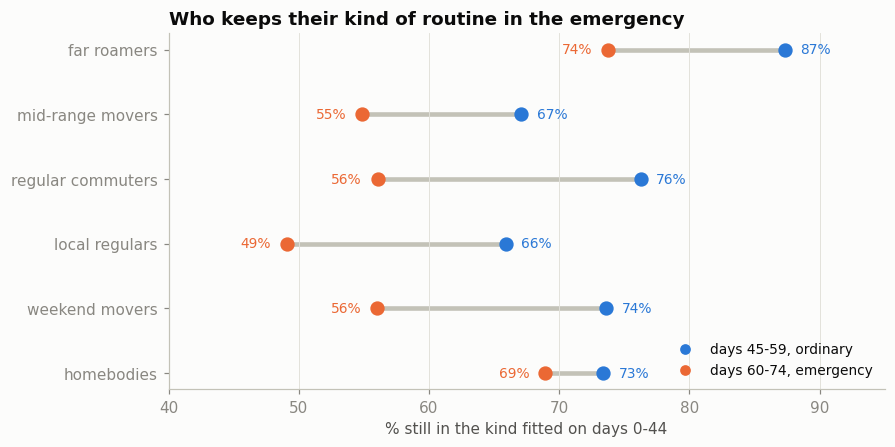

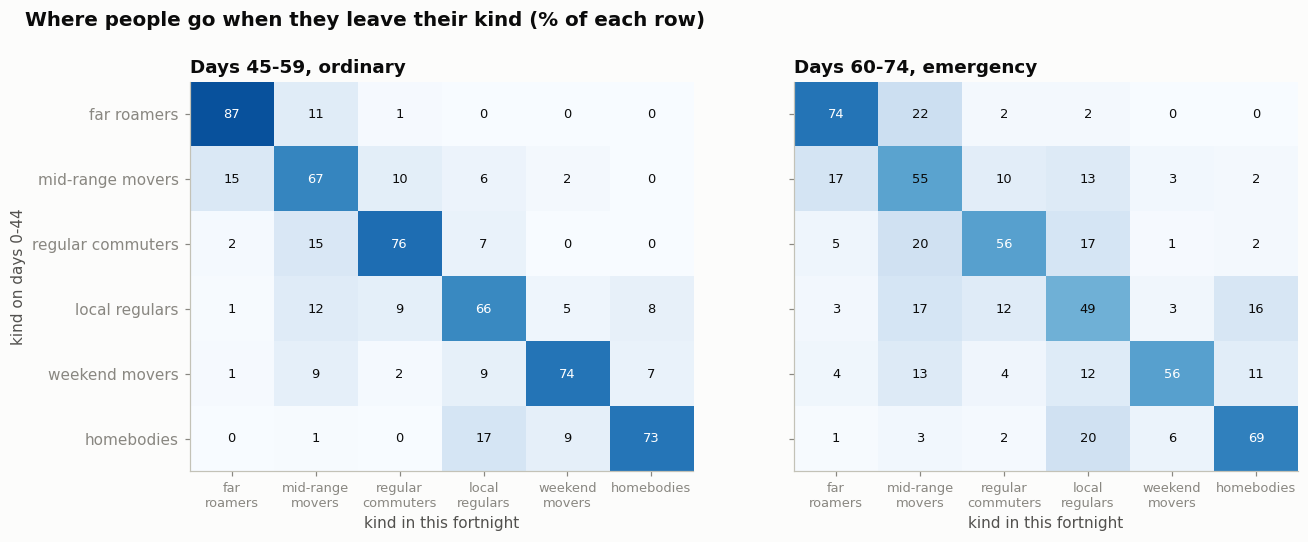

kind               far roamers  mid-range movers  regular commuters  local regulars  weekend movers  homebodies
ref_kind                                                                                                       
far roamers               74.0              22.0                2.0             2.0             0.0         0.0
mid-range movers          17.0              55.0               10.0            13.0             3.0         2.0
regular commuters          5.0              20.0               56.0            17.0             1.0         2.0
local regulars             3.0              17.0               12.0            49.0             3.0        16.0
weekend movers             4.0              13.0                4.0            12.0            56.0        11.0
homebodies                 1.0               3.0                2.0            20.0             6.0        69.0


In [25]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
yy = np.arange(len(ORDER))[::-1]
for y, nm in zip(yy, ORDER):
    a, b = by_kind.loc[nm, "B4 ordinary"] * 100, by_kind.loc[nm, "B5 emergency"] * 100
    ax.plot([b, a], [y, y], color="#c3c2b7", lw=3, zorder=1)
    ax.scatter(a, y, s=70, color=C[0], zorder=2); ax.scatter(b, y, s=70, color=C[1], zorder=2)
    ax.text(b - 1.2, y, f"{b:.0f}%", ha="right", va="center", fontsize=9, color=C[1]); ax.text(a + 1.2, y, f"{a:.0f}%", ha="left", va="center", fontsize=9, color=C[0])
ax.set_yticks(yy); ax.set_yticklabels(ORDER); ax.set_xlim(40, 95); ax.yaxis.grid(False)
ax.scatter([], [], color=C[0], label="days 45-59, ordinary"); ax.scatter([], [], color=C[1], label="days 60-74, emergency")
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set(xlabel="% still in the kind fitted on days 0-44")
ax.set_title("Who keeps their kind of routine in the emergency")
save(fig, "f25_kinds_persistence")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, b, ttl in zip(axes, [3, 4], ["Days 45-59, ordinary", "Days 60-74, emergency"]):
    t = pd.crosstab(blocks_all.ref_kind[blocks_all.block == b], blocks_all.kind[blocks_all.block == b], normalize="index").reindex(index=ORDER, columns=ORDER) * 100
    ax.imshow(t.values, cmap="Blues", vmin=0, vmax=100, aspect="auto"); ax.grid(False)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{t.values[i, j]:.0f}", ha="center", va="center", fontsize=8.5, color="white" if t.values[i, j] > 55 else "#0b0b0b")
    ax.set_xticks(range(6)); ax.set_xticklabels([textwrap.fill(n, 10) for n in ORDER], fontsize=8.5)
    ax.set_yticks(range(6)); ax.set_yticklabels(ORDER if b == 3 else [])
    ax.set_title(ttl); ax.set_xlabel("kind in this fortnight")
axes[0].set_ylabel("kind on days 0-44")
fig.suptitle("Where people go when they leave their kind (% of each row)", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.02)
save(fig, "f26_kinds_transitions")
t5 = pd.crosstab(blocks_all.ref_kind[blocks_all.block == 4], blocks_all.kind[blocks_all.block == 4], normalize="index").reindex(index=ORDER, columns=ORDER)
print((t5 * 100).round(0).to_string())

## Where people go when they leave their kind

Being "still in the kind" means that a person's new fortnight, measured with the same fifteen traits and placed against the same six frozen centres, is closest to the kind their days 0 to 44 gave them. Nothing is refitted; only the person's behaviour is measured again.

The two tables show where the others go, and in the emergency the moves have a direction. Regular commuters who leave their kind become mid-range movers (20%) or local regulars (17%), far roamers become mid-range movers (22%), mid-range movers become local regulars (13%), and local regulars become homebodies (16%). In the ordinary fortnight the off-diagonal moves go both ways in similar amounts and stay small. In the emergency people do not scatter across the map of kinds, they step toward the rooted end of it: a smaller range, fewer fixed weekday places, more time near home. The one exception runs the other way: 17% of mid-range movers become far roamers, about as many as in the ordinary fortnight (15%).

In [26]:
# is it behaviour or recording? (1) people whose records per day hardly changed, (2) the same test after randomly dropping 30% of records
from profiles import profiles
b4 = blocks_all[blocks_all.block == 3].set_index("uid"); b5 = blocks_all[blocks_all.block == 4].set_index("uid")
both = b4.index.intersection(b5.index)
change = b5.records_per_day[both] / b4.records_per_day[both] - 1
print(f"people in both fortnights: {len(both):,}; median change in records per day {change.median():+.1%}")
for label, idx in [("everyone", both), ("records per day within 10%", both[change.abs() < 0.10]), ("records per day down more than 20%", both[change < -0.20])]:
    print(f"  {label:36s} n={len(idx):6,}  ordinary {b4.same[idx].mean():.3f}  emergency {b5.same[idx].mean():.3f}")

late = an[an.d >= 45][["uid", "d", "t", "x", "y", "weekend", "holiday_like", "adjacent", "step_prev", "workday"]].copy()
keep = np.random.default_rng(SEED + 18).random(len(late)) < 0.7
thin = late[keep].copy()
thin["block"] = (thin.d // BLOCK_DAYS).astype("int8"); thin["cell"] = (thin.x.astype("int32") * 256 + thin.y).astype("int32")
# adjacency and steps have to be recomputed on the thinned records
same_uid = thin.uid.values[1:] == thin.uid.values[:-1]
gap = (thin.d.values[1:].astype("int32") - thin.d.values[:-1]) * 48 + (thin.t.values[1:].astype("int32") - thin.t.values[:-1])
step = np.maximum(np.abs(np.diff(thin.x.values.astype("int32"))), np.abs(np.diff(thin.y.values.astype("int32"))))
thin["adjacent"] = np.r_[False, same_uid & (gap == 1)]; thin["step_prev"] = np.r_[0, step].astype("int16")
tp = profiles(thin, anc)
tp = tp[tp.eligible_block & tp.uid.isin(ref.index)].set_index("uid")
for b, full in [(3, b4), (4, b5)]:
    t = tp[tp.block == b]
    xt = prepare(t).fillna(prepare(ref.loc[t.index]))
    kt = pd.Series(km6.predict(scaler.transform(xt)), index=t.index).map(name)
    idx = kt.index.intersection(full.index)
    print(f"{blk_name[b]:13s} same kind as with all records: {np.mean(kt[idx] == full.kind[idx]):.3f} | in reference kind: all records {full.same[idx].mean():.3f}, 70% of records {np.mean(kt[idx] == full.ref_kind[idx]):.3f}")
del late, thin, tp

people in both fortnights: 23,759; median change in records per day -12.4%
  everyone                             n=23,759  ordinary 0.740  emergency 0.595
  records per day within 10%           n= 5,587  ordinary 0.744  emergency 0.636
  records per day down more than 20%   n= 9,044  ordinary 0.758  emergency 0.586
B4 ordinary   same kind as with all records: 0.903 | in reference kind: all records 0.741, 70% of records 0.731
B5 emergency  same kind as with all records: 0.901 | in reference kind: all records 0.595, 70% of records 0.587


## Behaviour or recording?

People are recorded less in the emergency, a median 12.4% fewer records per day, so part of the drop could come from thinner data rather than different behaviour. Two checks bound that. First, among the 5,587 people whose records per day changed by less than 10% between the two fortnights, 74.4% keep their kind in the ordinary fortnight and 63.6% in the emergency: a drop of 10.8 points, against 14.5 points for everyone. People who lost more than a fifth of their records drop by 17.2 points. So recording explains part of the effect, at most about a quarter of it, and three quarters remain among people who were seen just as often. Second, randomly removing 30% of every person's records from days 45 to 74 and recomputing all traits changes the assigned kind for only one fortnight in ten, and leaves the share still in their kind almost where it was (0.741 to 0.731 ordinary, 0.595 to 0.587 emergency). The traits are rates and shares, so they hold up when records thin out at random. Together the checks say the change of kind in the emergency is mostly a change in how people move. What they cannot rule out is recording that thins out in a way tied to movement, which is the open part of question 2.

                   dist_own_centre B4  dist_own_centre B5  recon_error B4  recon_error B5
ref_kind                                                                                 
far roamers                      2.24                2.39            1.39            1.50
mid-range movers                 2.67                2.92            1.59            1.75
regular commuters                2.65                3.17            1.59            1.79
local regulars                   3.31                3.70            1.86            2.02
weekend movers                   3.47                3.91            1.94            2.01
homebodies                       3.55                3.89            2.02            2.15

all people, median: {'dist_own_centre': {'B4 ordinary': 2.81, 'B5 emergency': 3.15}, 'recon_error': {'B4 ordinary': 1.65, 'B5 emergency': 1.8}}
night-mobile development people still in their kind: ordinary 0.798, emergency 0.646 | other development people 0.737, 0.591


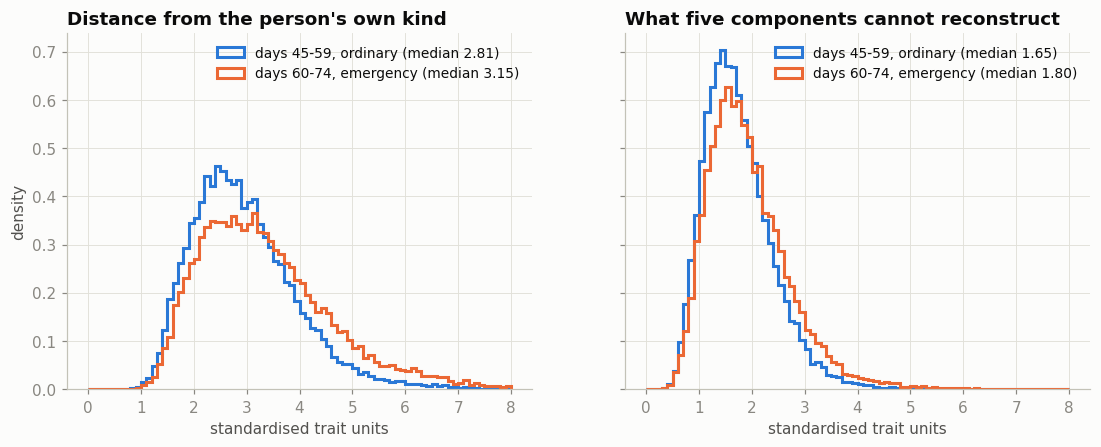

In [27]:
# drift signal for the later studies: distance of each fortnight from the person's own kind centre, and how badly the
# five frozen components reconstruct it (both measured in standardised trait units)
inv = {v: k for k, v in name.items()}
Zb = scaler.transform(x)
blocks_all["dist_own_centre"] = np.linalg.norm(Zb - km6.cluster_centers_[blocks_all.ref_kind.map(inv).to_numpy()], axis=1)
P5 = pca.components_[:k80]
blocks_all["recon_error"] = np.linalg.norm(Zb - (Zb @ P5.T) @ P5, axis=1)
blocks_all["night_mobile"] = night.night_mobile.reindex(blocks_all.uid).to_numpy()
d = blocks_all[blocks_all.block >= 3]
tab = d.groupby(["ref_kind", "block"])[["dist_own_centre", "recon_error"]].median().unstack().loc[ORDER]
tab.columns = [f"{a} {blk_name[b].split()[0]}" for a, b in tab.columns]
print(tab.round(2).to_string())
print("\nall people, median:", d.groupby("block")[["dist_own_centre", "recon_error"]].median().rename(index=blk_name).round(2).to_dict())
nm = d[d.night_mobile == True].groupby("block").same.mean(); rest_ = d[d.night_mobile == False].groupby("block").same.mean()
print(f"night-mobile development people still in their kind: ordinary {nm[3]:.3f}, emergency {nm[4]:.3f} | other development people {rest_[3]:.3f}, {rest_[4]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, ttl in zip(axes, ["dist_own_centre", "recon_error"], ["Distance from the person's own kind", "What five components cannot reconstruct"]):
    for b, c_, lab in [(3, C[0], "days 45-59, ordinary"), (4, C[1], "days 60-74, emergency")]:
        v = d[d.block == b][col]
        ax.hist(v, bins=np.linspace(0, 8, 81), density=True, histtype="step", lw=2, color=c_, label=f"{lab} (median {v.median():.2f})")
    ax.set(xlabel="standardised trait units", title=ttl); ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("density")
save(fig, "f27_drift_signal")

## A drift signal

Whether a person changed kind is a yes or no. Two continuous measures say how far a fortnight has moved, both through the frozen model and both in standardised trait units: the distance from the centre of the person's own kind, and the part of the fortnight's fifteen traits that the five frozen components cannot reconstruct. Both shift up in the emergency: the median distance from the own centre grows from 2.81 to 3.15 and the reconstruction error from 1.65 to 1.80, with a longer tail of people far from where they used to be. Regular commuters show the largest growth in distance (2.65 to 3.17), far roamers the smallest (2.24 to 2.39). These are the kind of numbers a model of a person could watch to notice that the person has changed, and they come back in the research extension, where an agent has to decide when to update itself.

The night-mobile people keep their kind more often than the rest (80% ordinary and 65% emergency, against 74% and 59%), because most of them are far roamers, the most stable kind. A weak night anchor does not make a person's kind less reliable.

cells with POI: 19,998 | median places per cell 9
explained variance % (first 10): [27.1  4.7  2.9  1.9  1.8  1.6  1.4  1.4  1.2  1.2]
components for 80%: 48 | for 90%: 63 | eigenvalue above 1: 13
PC1 against log of all places in the cell, correlation: 0.808 | PC1 loadings all positive: True
PC2 high: cat12, cat25, cat27, cat49, cat6, cat22 | low: cat59, cat60, cat79, cat54, cat63, cat69
PC3 high: cat44, cat35, cat26, cat32, cat45, cat40 | low: cat24, cat29, cat77, cat12, cat22, cat78


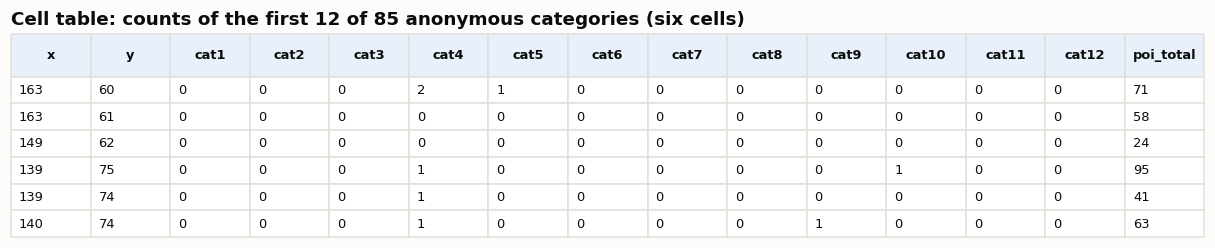

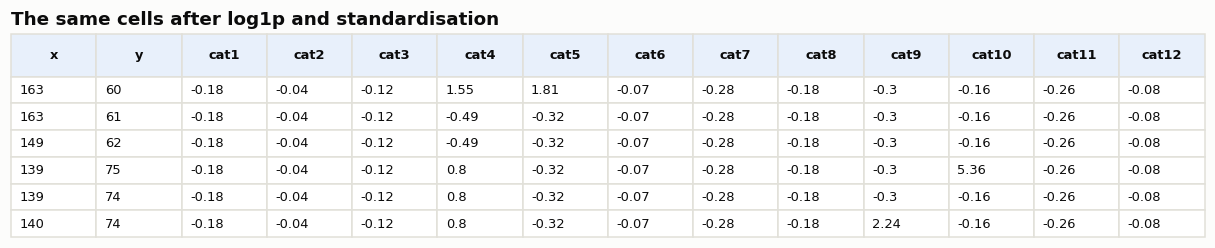

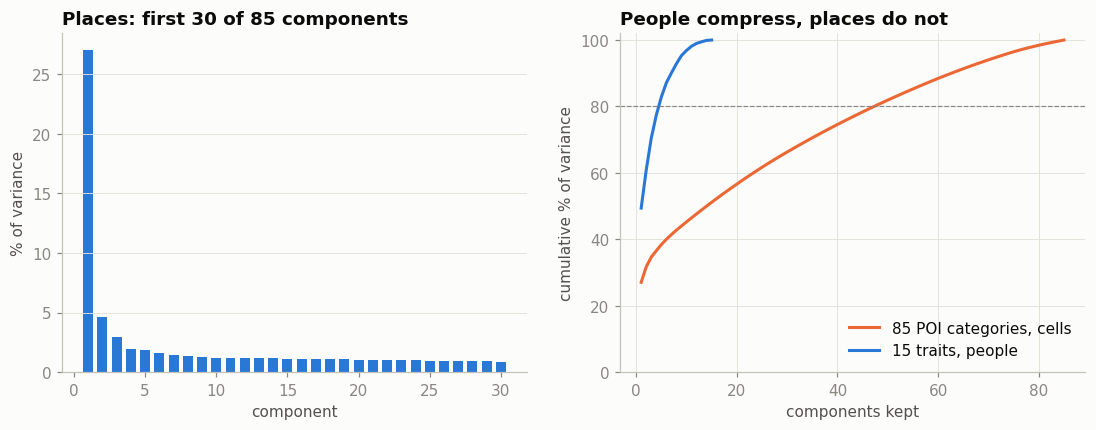

In [28]:
# the same tool on places: occupied cells x 85 anonymous POI categories, log1p counts, standardised
cells = pd.read_parquet(PROC / "cell_table.parquet")
cats = [c for c in cells.columns if c.startswith("cat")]
poi = cells[cells.has_poi]
Xp = np.log1p(poi[cats].to_numpy(dtype="float64"))
scaler_p = StandardScaler().fit(Xp); Zp = scaler_p.transform(Xp)
pca_p = PCA().fit(Zp); evr_p = pca_p.explained_variance_ratio_; cum_p = np.cumsum(evr_p)
print(f"cells with POI: {len(poi):,} | median places per cell {poi.poi_total.median():.0f}")
print("explained variance % (first 10):", (evr_p[:10] * 100).round(1))
print(f"components for 80%: {np.argmax(cum_p >= 0.8) + 1} | for 90%: {np.argmax(cum_p >= 0.9) + 1} | eigenvalue above 1: {(pca_p.explained_variance_ > 1).sum()}")
Sp = pd.DataFrame(pca_p.transform(Zp)[:, :4], index=poi.index, columns=["PC1", "PC2", "PC3", "PC4"])
if np.corrcoef(Sp.PC1, np.log1p(poi.poi_total))[0, 1] < 0: Sp.PC1 *= -1; pca_p.components_[0] *= -1
print("PC1 against log of all places in the cell, correlation:", np.corrcoef(Sp.PC1, np.log1p(poi.poi_total))[0, 1].round(3),
      "| PC1 loadings all positive:", bool((pca_p.components_[0] > -0.01).all()))
lp = pd.DataFrame(pca_p.components_[:4].T, index=cats, columns=["PC1", "PC2", "PC3", "PC4"])
for c in ["PC2", "PC3"]:
    print(f"{c} high: {', '.join(lp[c].nlargest(6).index)} | low: {', '.join(lp[c].nsmallest(6).index)}")
table_png(poi[cats[:12] + ["poi_total"]].head(6).reset_index(), "t09_cell_poi_counts", "Cell table: counts of the first 12 of 85 anonymous categories (six cells)", 14)
table_png(pd.DataFrame(Zp[:6, :12], columns=cats[:12], index=poi.index[:6]).round(2).reset_index(), "t10_cell_poi_scaled", "The same cells after log1p and standardisation", 14)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pcs_p = np.arange(1, 31)
axes[0].bar(pcs_p, evr_p[:30] * 100, color=C[0], width=0.7); axes[0].set(xlabel="component", ylabel="% of variance", title="Places: first 30 of 85 components"); axes[0].xaxis.grid(False)
axes[1].plot(np.arange(1, 86), cum_p * 100, color=C[1], lw=2, label="85 POI categories, cells")
axes[1].plot(np.arange(1, 16), cum * 100, color=C[0], lw=2, label="15 traits, people")
axes[1].axhline(80, color="#898781", lw=0.8, ls="--")
axes[1].set(xlabel="components kept", ylabel="cumulative % of variance", title="People compress, places do not", ylim=(0, 102)); axes[1].legend(frameon=False, loc="lower right")
save(fig, "f28_pca_places_scree")

## Places do not compress like people

The cell table has one row per occupied 500 m cell with at least one point of interest, 19,998 of them, and 85 columns counting places of each anonymous category; the median cell has 9 places. Counts are log(1 + x) transformed and standardised, so a category with thousands of places and one with a handful weigh the same. PCA on this table behaves very differently from PCA on people. The first component carries 27.1% and has a loading of the same sign on every one of the 85 categories: it says how many places a cell has of any kind (correlation 0.81 with the log of all places). After it the spectrum is flat. The second component carries 4.7%, the third 2.9%, and from there each adds one or two percent; 48 components are needed for 80% and 63 for 90%. Fifteen traits of people collapse into five components; 85 categories of places do not collapse at all beyond "how much is here". Places are made of many small independent mixtures, and the course question of how few dimensions are enough has a different answer for each table. PC2 and PC3 set groups of categories against each other (PC2: categories 12, 25, 27, 49, 6 and 22 against 59, 60, 79, 54, 63 and 69); since the categories are anonymous, the next cells read them through the rhythm of the cells instead of their names.

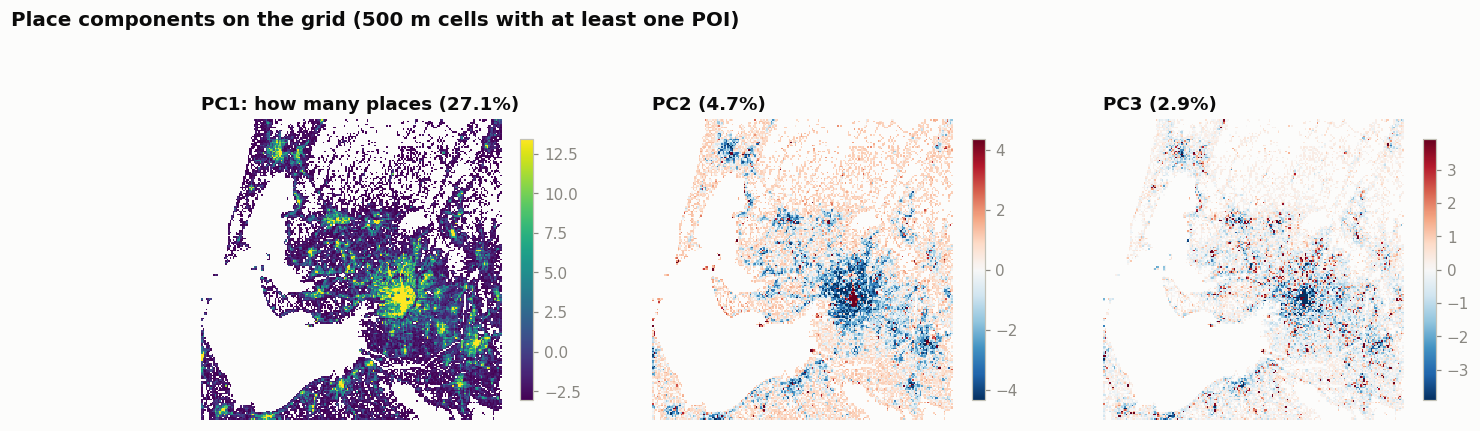

In [29]:
# the first three place components on the 200 x 200 grid
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
xs, ys = Sp.index.get_level_values("x").to_numpy(), Sp.index.get_level_values("y").to_numpy()
for ax, c, cm, ttl in zip(axes, ["PC1", "PC2", "PC3"], ["viridis", "RdBu_r", "RdBu_r"], ["PC1: how many places", "PC2", "PC3"]):
    grid = np.full((200, 200), np.nan); grid[ys - 1, xs - 1] = Sp[c].to_numpy()
    lim = np.nanpercentile(np.abs(grid), 98)
    im = ax.imshow(grid, origin="lower", cmap=cm, vmin=(np.nanpercentile(grid, 2) if c == "PC1" else -lim), vmax=(np.nanpercentile(grid, 98) if c == "PC1" else lim), interpolation="nearest")
    ax.set_title(f"{ttl} ({evr_p[int(c[-1]) - 1]:.1%})"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s_ in ax.spines.values(): s_.set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.7)
fig.suptitle("Place components on the grid (500 m cells with at least one POI)", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.03)
save(fig, "f29_pca_places_maps")

## The place components on the grid

Drawn on the grid in the same orientation as the occupancy and POI maps of the DataPrep tab, the first component is the density map again: bright in the dense core and along the corridors, dark in the sparse outer cells. The second component is spatial too, without having been told anything about space: its negative end (blue) fills the dense core and the larger centres around it, and its positive end (red) covers the outer cells. So the categories loading positively on PC2 are the ones typical of the periphery and the negative ones are typical of central places, beyond simply having more of everything. The third component is a patchwork of single cells within the core, a local mix rather than a centre-periphery contrast. Without names for the 85 categories these axes cannot be labelled by their content; the next step reads them through when people are in those cells.

In [30]:
# the rhythm of a place: share of a cell's records in each half hour, workdays and rest days separately, days 0-59
pre = an[an.d < 60][["x", "y", "t", "workday"]]
cnt = pre.groupby(["x", "y", "workday", "t"]).size().rename("n").reset_index()
tot = cnt.groupby(["x", "y"]).n.sum()
busy = tot[tot >= 500].index
print(f"cells with records on days 0-59: {len(tot):,}; with at least 500 records: {len(busy):,}, holding {tot[busy].sum() / tot.sum():.1%} of the records")
prof_c = cnt.set_index(["x", "y"]).loc[busy].reset_index().pivot_table(index=["x", "y"], columns=["workday", "t"], values="n", fill_value=0)
prof_c = prof_c.reindex(columns=pd.MultiIndex.from_product([[True, False], range(48)]), fill_value=0)
R = prof_c.to_numpy(dtype="float64")
R[:, :48] /= R[:, :48].sum(axis=1, keepdims=True).clip(min=1); R[:, 48:] /= R[:, 48:].sum(axis=1, keepdims=True).clip(min=1)
sub_c = np.random.default_rng(SEED + 22).choice(len(R), 5000, replace=False)
rows = []
for k in range(2, 9):
    kmc = KMeans(k, n_init=10, random_state=SEED).fit(R)
    rows.append((k, kmc.inertia_, silhouette_score(R[sub_c], kmc.labels_[sub_c])))
print(pd.DataFrame(rows, columns=["k", "wcss", "silhouette"]).set_index("k").round(4).to_string())
del pre

cells with records on days 0-59: 29,251; with at least 500 records: 11,858, holding 92.3% of the records
      wcss  silhouette
k                     
2  82.4267      0.1480
3  76.5555      0.1034
4  73.7183      0.0656
5  71.6855      0.0602
6  70.3256      0.0413
7  69.1952      0.0412
8  68.4346      0.0367


## The rhythm of a place

Instead of naming the anonymous categories, each cell can be described by when people are in it. For every cell with at least 500 records on days 0 to 59 (11,858 cells holding 92% of all records) the profile is the share of its records in each of the 48 half hours, separately for workdays and for rest days, 96 numbers that each sum to one per half. The size of the cell's crowd is divided out, so a busy and a quiet cell with the same timing look the same. k-means on these profiles finds no natural groups: the silhouette is 0.15 at k = 2 and falls to 0.06 at k = 5. Places differ by degree, from cells that fill at night to cells that fill at midday, with every mixture in between. I still cut the continuum into five rhythm types because five centres are enough to describe it and they read clearly in the next figure, but they are a description of a gradient, not kinds of places in the sense that the kinds of movers are.

            cells  workday_peak_hour  night_0_5h_%  midday_10_16h_%  evening_18_22h_%   PC1   PC2   PC3  records_%
peak 08:00   2501                  8          9.92            41.83             16.46  0.03 -0.37 -0.32      19.60
peak 12:00   1421                 12          4.28            53.78             11.09 -0.65  0.24 -0.05       9.49
peak 17:00   2883                 17          6.64            42.66             21.69  4.92 -0.54  0.47      30.30
peak 18:00   3446                 18         13.02            33.25             24.91  2.31 -1.01 -0.26      30.41
peak 20:00   1607                 20         23.70            24.23             25.24 -0.42 -0.43 -0.24      10.20


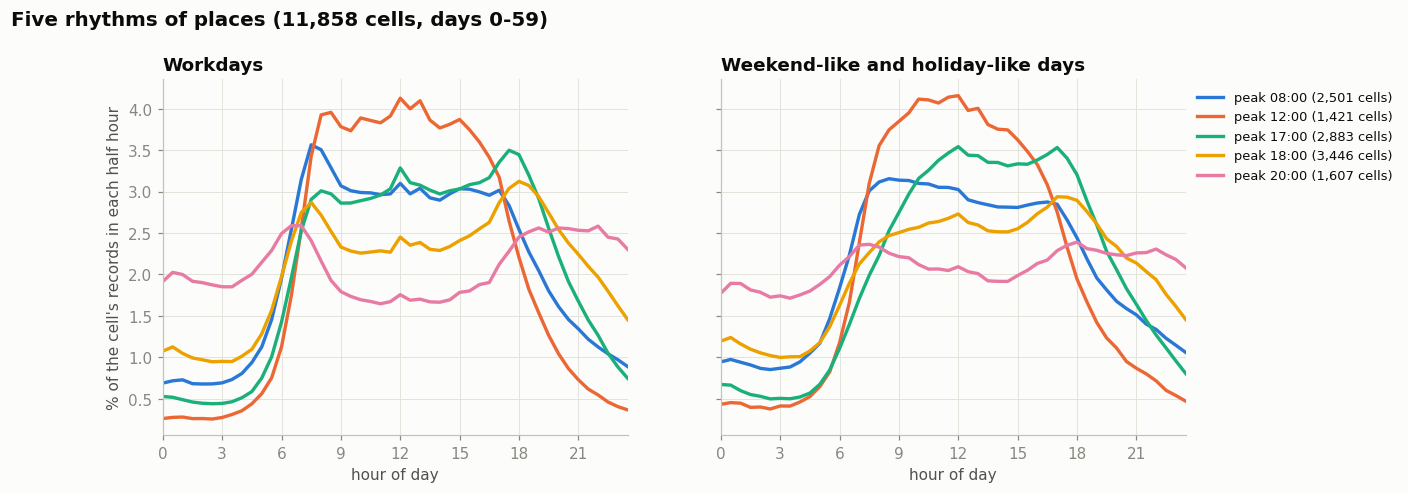

In [31]:
# five rhythm types of places; the silhouette is low at every k, so this is a description of a continuum, not a set of islands
KC = 5
kmc = KMeans(KC, n_init=10, random_state=SEED).fit(R)
cent_c = kmc.cluster_centers_
hourly = lambda v: np.add.reduceat(v, np.arange(0, 48, 2)) * 100
summ = pd.DataFrame({"cells": np.bincount(kmc.labels_),
                     "workday_peak_hour": [int(hourly(c[:48]).argmax()) for c in cent_c],
                     "night_0_5h_%": [hourly(c[:48])[:6].sum() for c in cent_c],
                     "midday_10_16h_%": [hourly(c[:48])[10:17].sum() for c in cent_c],
                     "evening_18_22h_%": [hourly(c[:48])[18:23].sum() for c in cent_c]})
place_lab = pd.Series(kmc.labels_, index=prof_c.index)
summ = summ.join(Sp.join(place_lab.rename("r"), how="inner").groupby("r")[["PC1", "PC2", "PC3"]].mean())
summ["records_%"] = tot[busy].groupby(place_lab.to_numpy()).sum().to_numpy() / tot[busy].sum() * 100
summ = summ.sort_values("workday_peak_hour")
PLACE = {r: f"peak {h:02d}:00" for r, h in summ.workday_peak_hour.items()}              # rhythm types named by their workday peak
summ.index = summ.index.map(PLACE)
print(summ.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, half, ttl in zip(axes, [slice(0, 48), slice(48, 96)], ["Workdays", "Weekend-like and holiday-like days"]):
    for j, r in enumerate(PLACE):
        ax.plot(np.arange(48) / 2, cent_c[r, half] * 100, color=C[j], lw=2.2, label=f"{PLACE[r]} ({summ.cells[PLACE[r]]:,} cells)")
    ax.set(xlabel="hour of day", xticks=range(0, 25, 3), xlim=(0, 23.5), title=ttl)
axes[0].set_ylabel("% of the cell's records in each half hour")
axes[1].legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Five rhythms of places (11,858 cells, days 0-59)", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.03)
save(fig, "f30_place_rhythms")

## Five rhythms of places

Named by when they peak on workdays, the five rhythm types describe the gradient. Peak 08:00 cells (2,501, 20% of records) fill sharply in the early morning and stay busy through the working day. Peak 12:00 cells (1,421, 9% of records) are the most daytime-only places: 54% of their workday records fall between 10 am and 4 pm, only 4% at night, and on rest days they are just as concentrated around noon. Peak 17:00 cells (2,883, 30% of records) are busy all day with an afternoon peak. Peak 18:00 cells (3,446, 30% of records) are fullest in the evening. Peak 20:00 cells (1,607, 10% of records) hold a quarter of their records at night and look like places people return to: an early-morning peak as people leave, a dip through the day, and an evening rise.

The place components and the rhythms are related. The peak 17:00 and peak 18:00 types are the cells with many places (mean PC1 of 4.9 and 2.3), the busy centres; the peak 12:00 cells are the only type on the positive, outer side of PC2. So the second place component, which splits the categories into central and peripheral ones, also separates daytime-only places from the centres.

plain cosine (every pair alike, so not informative): min 0.42 max 0.96

centred cosine
             Transit  Food  Shopping/Services  Work/Institutions  Outdoors  Culture/Leisure  Nightlife  Home
peak 08:00     0.38 -0.41              -0.42               0.71      0.54             0.06      -0.76 -0.40
peak 12:00    -0.02 -0.14              -0.13               0.83      0.37             0.38      -0.83 -0.64
peak 17:00    -0.43  0.14               0.54               0.18     -0.26             0.37      -0.35 -0.65
peak 18:00     0.03  0.18               0.09              -0.86     -0.42            -0.41       0.88  0.66
peak 20:00     0.14  0.07              -0.18              -0.56     -0.07            -0.34       0.70  0.76

                       closest  score           second  second_score
peak 08:00  Work/Institutions   0.71         Outdoors          0.54
peak 12:00  Work/Institutions   0.83  Culture/Leisure          0.38
peak 17:00  Shopping/Services   0.54  Culture/Leisure     

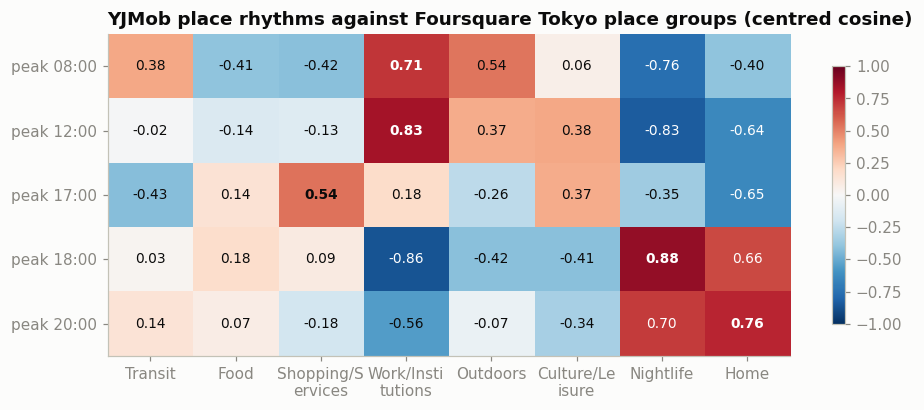

In [32]:
# a named mirror: the same rhythm for each Foursquare place group in Tokyo (check-ins by half hour, weekdays and weekends)
fs = pd.read_parquet(PROC / "foursquare_tky.parquet", columns=["local", "weekend", "group"])
fs["t"] = (fs.local.dt.hour * 2 + fs.local.dt.minute // 30).astype("int16")
T = fs.groupby(["group", "weekend", "t"]).size().unstack(fill_value=0).reindex(columns=range(48), fill_value=0)
GROUPS = ["Transit", "Food", "Shopping/Services", "Work/Institutions", "Outdoors", "Culture/Leisure", "Nightlife", "Home"]
tmpl = pd.DataFrame({g: np.r_[T.loc[(g, False)] / T.loc[(g, False)].sum(), T.loc[(g, True)] / T.loc[(g, True)].sum()] for g in GROUPS}).T
allfs = T.groupby(level="weekend").sum(); fs_mean = np.r_[allfs.loc[False] / allfs.loc[False].sum(), allfs.loc[True] / allfs.loc[True].sum()]

# compare shapes, not levels: each side minus its own average rhythm, then cosine similarity
def cos(a, b): return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
yj_mean = R.mean(axis=0)
att = pd.DataFrame({g: [cos(cent_c[r] - yj_mean, tmpl.loc[g].to_numpy() - fs_mean) for r in PLACE] for g in GROUPS}, index=list(PLACE.values()))
raw = pd.DataFrame({g: [cos(cent_c[r], tmpl.loc[g].to_numpy()) for r in PLACE] for g in GROUPS}, index=list(PLACE.values()))
print("plain cosine (every pair alike, so not informative): min", raw.values.min().round(2), "max", raw.values.max().round(2))
print("\ncentred cosine\n", att.round(2).to_string())
best = pd.DataFrame({"closest": att.idxmax(axis=1), "score": att.max(axis=1), "second": att.apply(lambda r: r.drop(r.idxmax()).idxmax(), axis=1),
                     "second_score": att.apply(lambda r: r.drop(r.idxmax()).max(), axis=1)})
print("\n", best.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 3.8)); ax.grid(False)
im = ax.imshow(att.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i in range(att.shape[0]):
    for j in range(att.shape[1]):
        v = att.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else "#0b0b0b",
                                      fontweight="bold" if j == np.argmax(att.values[i]) else "normal")
ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels([textwrap.fill(g, 10) for g in GROUPS]); ax.set_yticks(range(len(att))); ax.set_yticklabels(att.index)
ax.set_title("YJMob place rhythms against Foursquare Tokyo place groups (centred cosine)"); fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "f31_place_rhythms_vs_foursquare")

## A named mirror from Foursquare

The YJMob categories have no names, but the Foursquare check-ins from Tokyo do, and every check-in has a time. So the same 96-number rhythm can be built for each of the eight Foursquare place groups and compared with the five YJMob rhythm types. Compared directly, every pair looks alike (cosine 0.42 to 0.96), because both data sets share the basic shape of a day: quiet at night, busy in the day. The comparison becomes informative after subtracting from each side its own average rhythm, so that only the way a type deviates from an ordinary place is compared. With that centred cosine, peak 12:00 cells match Work/Institutions (0.83) and peak 08:00 cells match it too (0.71, then Outdoors 0.54 and Transit 0.38); peak 17:00 cells match Shopping/Services (0.54); peak 18:00 cells match Nightlife (0.88) and Home (0.66); and peak 20:00 cells match Home (0.76) and Nightlife (0.70).

These are inferred labels, not names the dataset contains. A rhythm says when people are in a cell, not what the cell is, and the two sources differ in how they record people: YJMob records a phone, Foursquare records a person who chose to check in, which is why evening leisure and home look alike here. The check-ins are also from a different provider and from 2012-13, and the two grids are never aligned. What the match does say is that the five rhythm types sort into work-like, shopping-like and evening or home-like places in a way consistent with named places in a Japanese city.

fortnight             emergency  ordinary  change_%
r          day                                     
peak 20:00 rest days     153396    186885     -17.9
           workdays      314908    362603     -13.2
peak 18:00 rest days     461208    522579     -11.7
           workdays     1044540   1129523      -7.5
peak 12:00 rest days      93634    118072     -20.7
           workdays      353928    418459     -15.4
peak 08:00 rest days     234654    279216     -16.0
           workdays      712480    817033     -12.8
peak 17:00 rest days     442185    498708     -11.3
           workdays     1077384   1167146      -7.7

share of records by rhythm type (%)
 fortnight   emergency  ordinary
r                              
peak 20:00       9.58      9.99
peak 18:00      30.80     30.04
peak 12:00       9.16      9.75
peak 08:00      19.38     19.93
peak 17:00      31.09     30.29


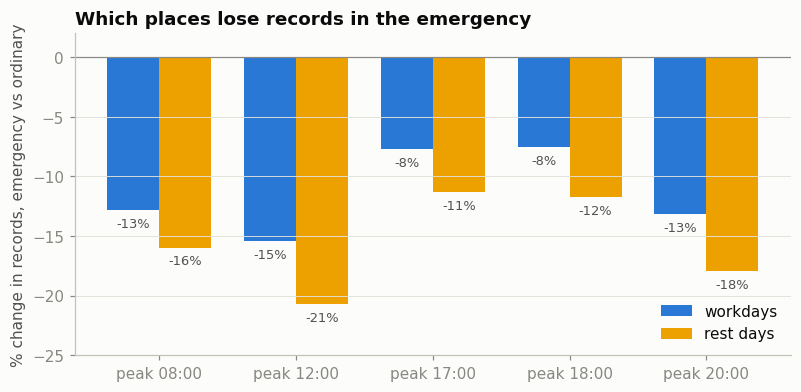

In [33]:
# which rhythm types of places lose records in the emergency? ordinary fortnight against emergency fortnight, same day types
late = an[an.d >= 45][["x", "y", "d", "workday"]]
late = late.join(place_lab.rename("r"), on=["x", "y"]).dropna(subset=["r"])
late["fortnight"] = np.where(late.d >= 60, "emergency", "ordinary")
late["day"] = np.where(late.workday, "workdays", "rest days")
n = late.groupby(["r", "day", "fortnight"]).size().unstack("fortnight")
n["change_%"] = (n.emergency / n.ordinary - 1) * 100
n = n.rename(index=PLACE, level=0)
print(n.round(1).to_string())
share = late.groupby(["fortnight", "r"]).size().unstack("fortnight"); share = (share / share.sum() * 100).rename(index=PLACE)
print("\nshare of records by rhythm type (%)\n", share.round(2).to_string())

fig, ax = plt.subplots(figsize=(8.4, 3.8))
order_p = list(PLACE.values()); w = 0.38; xx = np.arange(len(order_p))
for k_, (day, col) in enumerate([("workdays", C[0]), ("rest days", C[3])]):
    v = n.xs(day, level="day")["change_%"].reindex(order_p)
    ax.bar(xx + (k_ - 0.5) * w, v, width=w, color=col, label=day)
    for xi, vi in zip(xx + (k_ - 0.5) * w, v): ax.text(xi, vi - 0.6, f"{vi:.0f}%", ha="center", va="top", fontsize=8.5, color="#52514e")
ax.axhline(0, color="#898781", lw=0.8); ax.xaxis.grid(False)
ax.set_xticks(xx); ax.set_xticklabels(order_p); ax.set(ylabel="% change in records, emergency vs ordinary", ylim=(-25, 2))
ax.legend(frameon=False, loc="lower right"); ax.set_title("Which places lose records in the emergency")
save(fig, "f32_place_rhythms_emergency")
del late

## Which places lose records in the emergency

Counting the records that fall into each rhythm type in the ordinary fortnight and in the emergency fortnight, day type by day type (both fortnights have ten workdays and five rest days), every type loses records, because everyone is recorded less. The losses are not even. The midday-only places, the ones most like workplaces, lose the most: 15% on workdays and 21% on rest days. The early-peak and the home-like evening places come next (13% and 16%, 13% and 18%). The dense afternoon and evening centres lose the least, 8% on workdays and 11 to 12% on rest days, so their share of all records grows slightly, from 60.3% to 61.9%. It is the place-level counterpart of what the kinds of movers showed: fewer days at a fixed workplace, and what activity remains drawn a little more toward the busy centres.

In [34]:
# outputs: tables for the later studies, the frozen model, small samples for the site
import joblib
SAMPLE = ROOT / "data/samples"; SAMPLE.mkdir(parents=True, exist_ok=True)
kinds = pd.DataFrame({"split": ref.split, "kind": ref_kind}).join(
    pd.DataFrame(pca.transform(scaler.transform(prepare(ref)))[:, :k80], index=ref.index, columns=[f"pc{i}" for i in range(1, k80 + 1)]))
kinds["night_mobile"] = night.night_mobile.reindex(kinds.index)
kinds.to_parquet(PROC / "person_kinds.parquet")
blocks_all[["uid", "block", "split", "ref_kind", "kind", "same", "dist_own_centre", "recon_error"] + BEHAVIOUR + OBSERVABILITY].to_parquet(PROC / "person_blocks_kinds.parquet", index=False)
places = Sp.join(place_lab.map(PLACE).rename("rhythm_type"), how="outer")
places.to_parquet(PROC / "place_types.parquet")
joblib.dump({"scaler": scaler, "pca": pca, "kmeans": km6, "log_traits": LOG, "traits": BEHAVIOUR, "kind_of_label": name,
             "scaler_poi": scaler_p, "pca_poi": pca_p, "kmeans_rhythm": kmc, "rhythm_type_of_label": PLACE}, PROC / "frozen_part2.joblib")
ref.sample(500, random_state=SEED).round(4).to_csv(SAMPLE / "person_traits_sample.csv")
poi[cats + ["poi_total"]].sample(500, random_state=SEED).to_csv(SAMPLE / "cell_poi_sample.csv")
log = {"reference_people": len(ref), "development": int((ref.split == "dev").sum()), "pca_components_80": k80, "pca_evr_top5": evr[:5].round(4).tolist(),
       "k": K, "kind_sizes_dev": lab6.value_counts().to_dict(), "still_in_kind": {blk_name[b]: round(float(v), 4) for b, v in blocks_all.groupby("block").same.mean().items()},
       "poi_pca_components_80": int(np.argmax(cum_p >= 0.8) + 1), "rhythm_types": summ.cells.to_dict()}
(ROOT / "logs/part2_log.json").write_text(json.dumps(log, indent=2, default=int)); print(json.dumps(log, indent=2, default=int))
for p in ["person_kinds.parquet", "person_blocks_kinds.parquet", "place_types.parquet", "frozen_part2.joblib"]:
    print(f"{p:28s} {(PROC / p).stat().st_size / 1e6:6.1f} MB")

{
  "reference_people": 24514,
  "development": 17164,
  "pca_components_80": 5,
  "pca_evr_top5": [
    0.4941,
    0.1145,
    0.0959,
    0.0693,
    0.0545
  ],
  "k": 6,
  "kind_sizes_dev": {
    "mid-range movers": 4556,
    "far roamers": 3890,
    "local regulars": 3242,
    "regular commuters": 3020,
    "homebodies": 1428,
    "weekend movers": 1028
  },
  "still_in_kind": {
    "B1": 0.8123,
    "B2": 0.8294,
    "B3": 0.8181,
    "B4 ordinary": 0.7399,
    "B5 emergency": 0.5951
  },
  "poi_pca_components_80": 48,
  "rhythm_types": {
    "peak 08:00": 2501,
    "peak 12:00": 1421,
    "peak 17:00": 2883,
    "peak 18:00": 3446,
    "peak 20:00": 1607
  }
}
person_kinds.parquet            1.4 MB
person_blocks_kinds.parquet     9.5 MB
place_types.parquet             0.7 MB
frozen_part2.joblib             0.2 MB


## What this notebook found

Fifteen traits describe how a person moves over a fortnight, and five components carry 83% of their variation: how far a person ranges (49%), how strong their weekday routine is (11%), and three smaller axes, one of which partly measures how well a person is recorded. The 17,164 development people form one continuous cloud, not separate groups, so k was chosen by stability as well as silhouette, and six kinds of movers were kept: far roamers, mid-range movers, regular commuters, local regulars, weekend movers and homebodies, each with its own shape of day. Hierarchical clustering with cosine distance on 3,000 of them finds the same main split, rooted against wide-ranging, with regular commuters as the clearest group between.

With the six kinds frozen on days 0 to 44, 74% of people still fit their kind in an ordinary fortnight and 59% in the emergency, the same for people never used in the fit. Regular commuters, weekend movers and local regulars lose the most, homebodies almost nothing, and those who leave their kind move toward the rooted end. Thinner recording explains at most a quarter of this. Places, by contrast, do not reduce to a few components beyond how many places a cell has, and their daily rhythms form a gradient; workplace-like cells lose the most records in the emergency and the busy centres the least.

Outputs: data/processed/person_kinds.parquet, person_blocks_kinds.parquet, place_types.parquet, frozen_part2.joblib; samples in data/samples; figures f17 to f32 and t07 to t10; code/profiles.py; logs/part2_log.json.